In [1]:

# ==========================================
# SETUP GNN GRAPHCONVMODEL USP5
# ==========================================

import tensorflow as tf
import deepchem as dc

from deepchem.models import GraphConvModel
from deepchem.feat import ConvMolFeaturizer

print("=== ENVIRONMENT GNN USP5 ===")
print("TensorFlow:", tf.__version__)
print("DeepChem:", dc.__version__)
print("GraphConvModel: TERSEDIA")
print("ConvMolFeaturizer: TERSEDIA")
print("=== SETUP BERHASIL ===")


2026-11-03 05:39:31.192469: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-03 05:39:31.215851: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-03 05:39:31.215875: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-03 05:39:31.230897: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
No normalization for SPS. Feature removed!
No normal

Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead


Skipped loading modules with pytorch-geometric dependency, missing a dependency. No module named 'torch_geometric'
Skipped loading modules with transformers dependency. No module named 'transformers'
cannot import name 'HuggingFaceModel' from 'deepchem.models.torch_models' (/data/Aliya/usp5_env_baru/lib/python3.10/site-packages/deepchem/models/torch_models/__init__.py)
Skipped loading modules with pytorch-geometric dependency, missing a dependency. cannot import name 'DMPNN' from 'deepchem.models.torch_models' (/data/Aliya/usp5_env_baru/lib/python3.10/site-packages/deepchem/models/torch_models/__init__.py)
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'jax'


=== ENVIRONMENT GNN USP5 ===
TensorFlow: 2.16.2
DeepChem: 2.8.0
GraphConvModel: TERSEDIA
ConvMolFeaturizer: TERSEDIA
=== SETUP BERHASIL ===


In [2]:

# ==========================================
# 02. IMPORT DATA DAN FEATURIZATION
# GRAPHCONVMODEL USP5 - 82 SENYAWA
# ==========================================

import pandas as pd
import numpy as np
import deepchem as dc
from rdkit import Chem

# Dataset hasil kurasi KNIME
url = (
    "https://raw.githubusercontent.com/"
    "aliyarahmaazizah/USP5/main/USP5_pKd.csv"
)

df82 = pd.read_csv(url).reset_index(drop=True)

print("=== DATASET USP5 ===")
print("Jumlah senyawa:", len(df82))
print("Kolom:", df82.columns.tolist())

assert len(df82) == 82
assert df82[["Smiles", "pKd"]].notna().all().all()

# Canonical SMILES
mols = [Chem.MolFromSmiles(str(s)) for s in df82["Smiles"]]
assert all(m is not None for m in mols)

df82["Canonical_SMILES"] = [
    Chem.MolToSmiles(m, canonical=True, isomericSmiles=True)
    for m in mols
]

assert df82["Canonical_SMILES"].nunique() == 82

# Featurizer sesuai GraphConvModel lama
featurizer_gc = dc.feat.ConvMolFeaturizer()

X82_gc = featurizer_gc.featurize(
    df82["Canonical_SMILES"].tolist()
)

y82_gc = df82["pKd"].to_numpy(
    dtype=float
).reshape(-1, 1)

assert all(hasattr(g, "get_atom_features") for g in X82_gc)

# Dataset DeepChem
dataset82_gc = dc.data.NumpyDataset(
    X=X82_gc,
    y=y82_gc,
    ids=df82["Canonical_SMILES"].to_numpy()
)

print("\n=== HASIL FEATURIZATION ===")
print("Jumlah graf:", len(X82_gc))
print("Graf valid:", len(dataset82_gc))
print("Fitur atom:", X82_gc[0].get_atom_features().shape[1])
print("Shape target:", dataset82_gc.y.shape)
print("Duplikat SMILES:", df82["Canonical_SMILES"].duplicated().sum())

print("\n=== FEATURIZATION SELESAI ===")


=== DATASET USP5 ===
Jumlah senyawa: 82
Kolom: ['Molecule ChEMBL ID', 'Smiles', 'pKd']


[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATIO


=== HASIL FEATURIZATION ===
Jumlah graf: 82
Graf valid: 82
Fitur atom: 75
Shape target: (82, 1)
Duplikat SMILES: 0

=== FEATURIZATION SELESAI ===


[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[05:43:32] DEPRECATIO

In [3]:

# ==========================================
# 03. SPLIT DATA GRAPHCONVMODEL USP5 82
# SAMA DENGAN EKSPERIMEN GCN SEBELUMNYA
# ==========================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

root = Path("/data/Aliya/GCN_pKd_Stilben")

# Ambil split training/testing lama
with open(root / "Backup_Recovery/data_splits.json") as f:
    splits = json.load(f)

train_idx = np.array(splits["train_idx"], dtype=int)
test_idx = np.array(splits["test_idx"], dtype=int)

# Ambil 13 molekul validation dari GCN sebelumnya
file_validasi = (
    root /
    "GCN_Random_82_vs_80" /
    "Model_82_Seed42" /
    "Perbandingan_82_vs_80.csv"
)

assert file_validasi.exists(), (
    f"File validasi tidak ditemukan: {file_validasi}"
)

validasi_lama = pd.read_csv(file_validasi)
val_smiles = set(validasi_lama["SMILES"])

# Identitas seluruh molekul
ids = np.asarray(dataset82_gc.ids)

# Ambil validation yang sama
val_idx = np.array([
    i for i in train_idx
    if ids[i] in val_smiles
], dtype=int)

# Training = training lama, tanpa validation
tr_idx = np.array([
    i for i in train_idx
    if ids[i] not in val_smiles
], dtype=int)

# Bentuk dataset GraphConvModel
train_gc = dataset82_gc.select(tr_idx)
valid_gc = dataset82_gc.select(val_idx)
test_gc = dataset82_gc.select(test_idx)

# Pemeriksaan keamanan split
assert len(train_gc) == 53
assert len(valid_gc) == 13
assert len(test_gc) == 16

assert set(valid_gc.ids) == val_smiles
assert set(train_gc.ids).isdisjoint(set(valid_gc.ids))
assert set(test_gc.ids).isdisjoint(set(train_gc.ids))
assert set(test_gc.ids).isdisjoint(set(valid_gc.ids))

print("=== SPLIT GRAPHCONVMODEL USP5 ===")
print("Training:", len(train_gc))
print("Validation:", len(valid_gc))
print("Testing:", len(test_gc))
print("Validation sama dengan GCN: YA")
print("=== SPLIT BERHASIL ===")


=== SPLIT GRAPHCONVMODEL USP5 ===
Training: 53
Validation: 13
Testing: 16
Validation sama dengan GCN: YA
=== SPLIT BERHASIL ===


In [4]:

# ==========================================
# 04. TRAINING GRAPHCONVMODEL USP5
# DATASET 82 SENYAWA - 40 EPOCH
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Seed penelitian
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Folder eksperimen baru
output_dir = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/Original_40Epoch"
)
output_dir.mkdir(parents=True, exist_ok=True)

print("=== GRAPHCONVMODEL USP5 ===")
print("Training:", len(train_gc))
print("Validation:", len(valid_gc))
print("Testing terkunci:", len(test_gc))

# Arsitektur sesuai notebook lama
model_gc = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    learning_rate=0.001,
    dropout=0.0,
    batch_normalize=False,
    model_dir=str(output_dir / "Model")
)

# Training dengan pKd asli
# Sama seperti pendekatan notebook lama
print("\n=== TRAINING 40 EPOCH ===")

loss = model_gc.fit(
    train_gc,
    nb_epoch=40,
    checkpoint_interval=0
)

print("Training selesai!")
print("Loss:", loss)

# Evaluasi training dan validation
hasil = []

for nama, data in [
    ("TRAINING", train_gc),
    ("VALIDATION", valid_gc)
]:

    actual = np.asarray(data.y).reshape(-1)
    pred = np.asarray(
        model_gc.predict(data)
    ).reshape(-1)

    assert np.isfinite(pred).all()

    rmse = np.sqrt(
        mean_squared_error(actual, pred)
    )
    mae = mean_absolute_error(actual, pred)
    r2 = r2_score(actual, pred)

    hasil.append({
        "Dataset": nama,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    print(f"\n=== {nama} ===")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print(f"R2   : {r2:.4f}")

df_hasil_gc = pd.DataFrame(hasil)

df_hasil_gc.to_csv(
    output_dir / "GraphConv_40Epoch_Results.csv",
    index=False
)

print("\n=== GRAPHCONVMODEL SELESAI ===")


=== GRAPHCONVMODEL USP5 ===
Training: 53
Validation: 13
Testing terkunci: 16

=== TRAINING 40 EPOCH ===


2026-11-03 05:49:23.470838: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1928] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 31132 MB memory:  -> device: 0, name: Tesla V100-SXM2-32GB, pci bus id: 0000:0a:00.0, compute capability: 7.0


ImportError: `keras.optimizers.legacy` is not supported in Keras 3. When using `tf.keras`, to continue using a `tf.keras.optimizers.legacy` optimizer, you can install the `tf_keras` package (Keras 2) and set the environment variable `TF_USE_LEGACY_KERAS=True` to configure TensorFlow to use `tf_keras` when accessing `tf.keras`.

In [5]:

# CEK KOMPATIBILITAS KERAS
from importlib.util import find_spec
from importlib.metadata import version, PackageNotFoundError

print("=== CEK KERAS ===")

for nama in ["tensorflow", "keras", "tf-keras"]:
    try:
        print(nama, ":", version(nama))
    except PackageNotFoundError:
        print(nama, ": BELUM TERINSTAL")

print("tf_keras tersedia:", find_spec("tf_keras") is not None)


=== CEK KERAS ===
tensorflow : 2.16.2
keras : 3.12.4
tf-keras : 2.16.0
tf_keras tersedia: True


In [6]:

# SETUP KERAS 2 UNTUK GRAPHCONVMODEL
import os

os.environ["TF_USE_LEGACY_KERAS"] = "1"

print("Legacy Keras:", os.environ["TF_USE_LEGACY_KERAS"])


Legacy Keras: 1


In [1]:

import json
import shutil
from pathlib import Path
from jupyter_client.kernelspec import KernelSpecManager

manager = KernelSpecManager()

# Gunakan kernel Clean yang sudah ada
spec = manager.get_kernel_spec("usp5_deepchem_clean")
path = Path(spec.resource_dir) / "kernel.json"

# Backup konfigurasi lama
backup = path.with_name("kernel.json.backup")
if not backup.exists():
    shutil.copy2(path, backup)

# Aktifkan Keras 2 untuk kernel Clean
config = json.loads(path.read_text())
config.setdefault("env", {})
config["env"]["TF_USE_LEGACY_KERAS"] = "1"

path.write_text(json.dumps(config, indent=2) + "\n")

print("=== KONFIGURASI BERHASIL ===")
print("Kernel:", config["display_name"])
print("Legacy Keras:", config["env"]["TF_USE_LEGACY_KERAS"])
print("Kernel baru dibuat: TIDAK")


=== KONFIGURASI BERHASIL ===
Kernel: Python (USP5 DeepChem Clean)
Legacy Keras: 1
Kernel baru dibuat: TIDAK


In [2]:
import os
import tensorflow as tf

print("Legacy Keras:", os.environ.get("TF_USE_LEGACY_KERAS"))
print("Lokasi:", tf.keras.__file__)

optimizer = tf.keras.optimizers.legacy.Adam(
    learning_rate=0.001
)

print("Optimizer berhasil:", type(optimizer).__name__)

2026-11-03 05:58:39.715968: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-03 05:58:39.738217: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-03 05:58:39.738244: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-03 05:58:39.752973: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Legacy Keras: 1
Lokasi: /data/Aliya/usp5_env_baru/lib/python3.10/site-packages/tf_keras/api/_v2/keras/__init__.py
Optimizer berhasil: Adam


In [3]:

# ==========================================
# 02. IMPORT DATA DAN FEATURIZATION
# GRAPHCONVMODEL USP5 - 82 SENYAWA
# ==========================================

import pandas as pd
import numpy as np
import deepchem as dc
from rdkit import Chem

# Dataset hasil kurasi KNIME
url = (
    "https://raw.githubusercontent.com/"
    "aliyarahmaazizah/USP5/main/USP5_pKd.csv"
)

df82 = pd.read_csv(url).reset_index(drop=True)

print("=== DATASET USP5 ===")
print("Jumlah senyawa:", len(df82))
print("Kolom:", df82.columns.tolist())

assert len(df82) == 82
assert df82[["Smiles", "pKd"]].notna().all().all()

# Canonical SMILES
mols = [Chem.MolFromSmiles(str(s)) for s in df82["Smiles"]]
assert all(m is not None for m in mols)

df82["Canonical_SMILES"] = [
    Chem.MolToSmiles(m, canonical=True, isomericSmiles=True)
    for m in mols
]

assert df82["Canonical_SMILES"].nunique() == 82

# Featurizer sesuai GraphConvModel lama
featurizer_gc = dc.feat.ConvMolFeaturizer()

X82_gc = featurizer_gc.featurize(
    df82["Canonical_SMILES"].tolist()
)

y82_gc = df82["pKd"].to_numpy(
    dtype=float
).reshape(-1, 1)

assert all(hasattr(g, "get_atom_features") for g in X82_gc)

# Dataset DeepChem
dataset82_gc = dc.data.NumpyDataset(
    X=X82_gc,
    y=y82_gc,
    ids=df82["Canonical_SMILES"].to_numpy()
)

print("\n=== HASIL FEATURIZATION ===")
print("Jumlah graf:", len(X82_gc))
print("Graf valid:", len(dataset82_gc))
print("Fitur atom:", X82_gc[0].get_atom_features().shape[1])
print("Shape target:", dataset82_gc.y.shape)
print("Duplikat SMILES:", df82["Canonical_SMILES"].duplicated().sum())

print("\n=== FEATURIZATION SELESAI ===")


No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
No normalization for NumAmideBonds. Feature removed!
No normalization for NumAtomStereoCenters. Feature removed!
No normalization for NumBridgeheadAtoms. Feature removed!
No normalization for NumHeterocycles. Feature removed!
No normalization for NumSpiroAtoms. Feature removed!
No normalization for NumUnspecifiedAtomStereoCenters. Feature removed!
No normalization for Phi. Feature removed!


Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead


Skipped loading modules with pytorch-geometric dependency, missing a dependency. No module named 'torch_geometric'
Skipped loading modules with transformers dependency. No module named 'transformers'
cannot import name 'HuggingFaceModel' from 'deepchem.models.torch_models' (/data/Aliya/usp5_env_baru/lib/python3.10/site-packages/deepchem/models/torch_models/__init__.py)
Skipped loading modules with pytorch-geometric dependency, missing a dependency. cannot import name 'DMPNN' from 'deepchem.models.torch_models' (/data/Aliya/usp5_env_baru/lib/python3.10/site-packages/deepchem/models/torch_models/__init__.py)
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'jax'


=== DATASET USP5 ===
Jumlah senyawa: 82
Kolom: ['Molecule ChEMBL ID', 'Smiles', 'pKd']

=== HASIL FEATURIZATION ===
Jumlah graf: 82
Graf valid: 82
Fitur atom: 75
Shape target: (82, 1)
Duplikat SMILES: 0

=== FEATURIZATION SELESAI ===


[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:00:47] DEPRECATIO

In [4]:

# ==========================================
# 03. SPLIT DATA GRAPHCONVMODEL USP5 82
# SAMA DENGAN EKSPERIMEN GCN SEBELUMNYA
# ==========================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

root = Path("/data/Aliya/GCN_pKd_Stilben")

# Ambil split training/testing lama
with open(root / "Backup_Recovery/data_splits.json") as f:
    splits = json.load(f)

train_idx = np.array(splits["train_idx"], dtype=int)
test_idx = np.array(splits["test_idx"], dtype=int)

# Ambil 13 molekul validation dari GCN sebelumnya
file_validasi = (
    root /
    "GCN_Random_82_vs_80" /
    "Model_82_Seed42" /
    "Perbandingan_82_vs_80.csv"
)

assert file_validasi.exists(), (
    f"File validasi tidak ditemukan: {file_validasi}"
)

validasi_lama = pd.read_csv(file_validasi)
val_smiles = set(validasi_lama["SMILES"])

# Identitas seluruh molekul
ids = np.asarray(dataset82_gc.ids)

# Ambil validation yang sama
val_idx = np.array([
    i for i in train_idx
    if ids[i] in val_smiles
], dtype=int)

# Training = training lama, tanpa validation
tr_idx = np.array([
    i for i in train_idx
    if ids[i] not in val_smiles
], dtype=int)

# Bentuk dataset GraphConvModel
train_gc = dataset82_gc.select(tr_idx)
valid_gc = dataset82_gc.select(val_idx)
test_gc = dataset82_gc.select(test_idx)

# Pemeriksaan keamanan split
assert len(train_gc) == 53
assert len(valid_gc) == 13
assert len(test_gc) == 16

assert set(valid_gc.ids) == val_smiles
assert set(train_gc.ids).isdisjoint(set(valid_gc.ids))
assert set(test_gc.ids).isdisjoint(set(train_gc.ids))
assert set(test_gc.ids).isdisjoint(set(valid_gc.ids))

print("=== SPLIT GRAPHCONVMODEL USP5 ===")
print("Training:", len(train_gc))
print("Validation:", len(valid_gc))
print("Testing:", len(test_gc))
print("Validation sama dengan GCN: YA")
print("=== SPLIT BERHASIL ===")


=== SPLIT GRAPHCONVMODEL USP5 ===
Training: 53
Validation: 13
Testing: 16
Validation sama dengan GCN: YA
=== SPLIT BERHASIL ===


In [5]:

# ==========================================
# 04. TRAINING GRAPHCONVMODEL USP5
# DATASET 82 SENYAWA - 40 EPOCH
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Seed penelitian
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Folder eksperimen baru
output_dir = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/Original_40Epoch"
)
output_dir.mkdir(parents=True, exist_ok=True)

print("=== GRAPHCONVMODEL USP5 ===")
print("Training:", len(train_gc))
print("Validation:", len(valid_gc))
print("Testing terkunci:", len(test_gc))

# Arsitektur sesuai notebook lama
model_gc = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    learning_rate=0.001,
    dropout=0.0,
    batch_normalize=False,
    model_dir=str(output_dir / "Model")
)

# Training dengan pKd asli
# Sama seperti pendekatan notebook lama
print("\n=== TRAINING 40 EPOCH ===")

loss = model_gc.fit(
    train_gc,
    nb_epoch=40,
    checkpoint_interval=0
)

print("Training selesai!")
print("Loss:", loss)

# Evaluasi training dan validation
hasil = []

for nama, data in [
    ("TRAINING", train_gc),
    ("VALIDATION", valid_gc)
]:

    actual = np.asarray(data.y).reshape(-1)
    pred = np.asarray(
        model_gc.predict(data)
    ).reshape(-1)

    assert np.isfinite(pred).all()

    rmse = np.sqrt(
        mean_squared_error(actual, pred)
    )
    mae = mean_absolute_error(actual, pred)
    r2 = r2_score(actual, pred)

    hasil.append({
        "Dataset": nama,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    print(f"\n=== {nama} ===")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print(f"R2   : {r2:.4f}")

df_hasil_gc = pd.DataFrame(hasil)

df_hasil_gc.to_csv(
    output_dir / "GraphConv_40Epoch_Results.csv",
    index=False
)

print("\n=== GRAPHCONVMODEL SELESAI ===")


=== GRAPHCONVMODEL USP5 ===
Training: 53
Validation: 13
Testing terkunci: 16


2026-11-03 06:01:49.529532: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1928] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 31132 MB memory:  -> device: 0, name: Tesla V100-SXM2-32GB, pci bus id: 0000:0a:00.0, compute capability: 7.0



=== TRAINING 40 EPOCH ===
Training selesai!
Loss: 0.18479124307632447

=== TRAINING ===
RMSE : 0.4389
MAE  : 0.2168
R2   : 0.6950

=== VALIDATION ===
RMSE : 0.4148
MAE  : 0.3196
R2   : 0.4680

=== GRAPHCONVMODEL SELESAI ===


In [6]:

# ==========================================
# 05. SEED STABILITY GRAPHCONVMODEL USP5
# 82 SENYAWA - 40 EPOCH
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

seeds = [42, 123, 2026]

folder_seed = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/Seed_Stability"
)
folder_seed.mkdir(parents=True, exist_ok=True)

hasil_seed_gc = []

for seed in seeds:

    print(f"\n=== SEED {seed} ===", flush=True)

    tf.keras.backend.clear_session()

    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

    model = dc.models.GraphConvModel(
        n_tasks=1,
        mode="regression",
        graph_conv_layers=[64, 64],
        dense_layer_size=128,
        batch_size=10,
        learning_rate=0.001,
        dropout=0.0,
        batch_normalize=False,
        model_dir=str(folder_seed / f"Seed_{seed}")
    )

    model.fit(
        train_gc,
        nb_epoch=40,
        checkpoint_interval=0
    )

    actual = valid_gc.y.reshape(-1)

    pred = np.asarray(
        model.predict(valid_gc)
    ).reshape(-1)

    rmse = np.sqrt(
        mean_squared_error(actual, pred)
    )
    mae = mean_absolute_error(actual, pred)
    r2 = r2_score(actual, pred)

    hasil_seed_gc.append({
        "Seed": seed,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    print(
        f"RMSE={rmse:.4f} | "
        f"MAE={mae:.4f} | R2={r2:.4f}",
        flush=True
    )

df_seed_gc = pd.DataFrame(hasil_seed_gc)

print("\n=== HASIL GRAPHCONV SEMUA SEED ===")
display(df_seed_gc.round(4))

print("\n=== RATA-RATA DAN STD ===")
display(
    df_seed_gc[["RMSE", "MAE", "R2"]]
    .agg(["mean", "std"])
    .round(4)
)

df_seed_gc.to_csv(
    folder_seed / "GraphConv_Seed_Stability.csv",
    index=False
)

print("\n=== SEED STABILITY SELESAI ===")



=== SEED 42 ===
RMSE=0.4204 | MAE=0.3252 | R2=0.4536

=== SEED 123 ===
RMSE=0.4746 | MAE=0.3780 | R2=0.3038

=== SEED 2026 ===
RMSE=0.4818 | MAE=0.3850 | R2=0.2823

=== HASIL GRAPHCONV SEMUA SEED ===


,Seed,RMSE,MAE,R2
0,42,0.4204,0.3252,0.4536
1,123,0.4746,0.3780,0.3038
2,2026,0.4818,0.3850,0.2823



=== RATA-RATA DAN STD ===


,RMSE,MAE,R2
mean,0.4589,0.3627,0.3465
std,0.0336,0.0327,0.0933



=== SEED STABILITY SELESAI ===


In [7]:

# ==========================================
# 06. OPTIMASI EPOCH GRAPHCONVMODEL USP5
# DATASET 82 | EPOCH 10-100
# ==========================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import mean_squared_error, r2_score

assert os.environ.get("TF_USE_LEGACY_KERAS") == "1"
assert len(train_gc) == 53
assert len(valid_gc) == 13
assert len(test_gc) == 16

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

folder_epoch = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/Epoch_10_100"
)
folder_epoch.mkdir(parents=True, exist_ok=True)

model_epoch = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    learning_rate=0.001,
    dropout=0.0,
    batch_normalize=False,
    model_dir=str(folder_epoch / "Training")
)

hasil_epoch = []
best_rmse = float("inf")
best_epoch = None

print("=== OPTIMASI EPOCH GRAPHCONV USP5 ===")

for epoch in range(10, 101, 10):

    # Lanjutkan model yang sama sebanyak 10 epoch
    model_epoch.fit(
        train_gc,
        nb_epoch=10,
        checkpoint_interval=0
    )

    skor = {}

    for nama, data in [
        ("Train", train_gc),
        ("Val", valid_gc)
    ]:
        aktual = data.y.reshape(-1)
        prediksi = np.asarray(
            model_epoch.predict(data)
        ).reshape(-1)

        skor[f"{nama}_RMSE"] = np.sqrt(
            mean_squared_error(aktual, prediksi)
        )
        skor[f"{nama}_R2"] = r2_score(
            aktual, prediksi
        )

    hasil_epoch.append({
        "Epoch": epoch,
        **skor
    })

    # Simpan bobot terbaik berdasarkan RMSE validasi
    if skor["Val_RMSE"] < best_rmse:
        best_rmse = skor["Val_RMSE"]
        best_epoch = epoch

        model_epoch.save_checkpoint(
            max_checkpoints_to_keep=1,
            model_dir=str(folder_epoch / "Best_Model")
        )

    print(
        f"Epoch {epoch:3d} | "
        f"Train R2={skor['Train_R2']:.4f} | "
        f"Val RMSE={skor['Val_RMSE']:.4f} | "
        f"Val R2={skor['Val_R2']:.4f}",
        flush=True
    )

df_epoch_gc = pd.DataFrame(hasil_epoch)

print("\n=== HASIL OPTIMASI EPOCH ===")
display(df_epoch_gc.round(4))

print("\n=== EPOCH TERBAIK ===")
print("Epoch:", best_epoch)
print("Validation RMSE:", round(best_rmse, 4))
display(df_epoch_gc.loc[
    df_epoch_gc["Epoch"] == best_epoch
].round(4))

df_epoch_gc.to_csv(
    folder_epoch / "Epoch_Optimization.csv",
    index=False
)

print("\n=== OPTIMASI SELESAI ===")


=== OPTIMASI EPOCH GRAPHCONV USP5 ===
Epoch  10 | Train R2=0.4701 | Val RMSE=0.4195 | Val R2=0.4560
Epoch  20 | Train R2=0.6002 | Val RMSE=0.3915 | Val R2=0.5262
Epoch  30 | Train R2=0.6546 | Val RMSE=0.4172 | Val R2=0.4620
Epoch  40 | Train R2=0.6967 | Val RMSE=0.4201 | Val R2=0.4545
Epoch  50 | Train R2=0.7167 | Val RMSE=0.4459 | Val R2=0.3852
Epoch  60 | Train R2=0.7271 | Val RMSE=0.3810 | Val R2=0.5512
Epoch  70 | Train R2=0.7720 | Val RMSE=0.4489 | Val R2=0.3769
Epoch  80 | Train R2=0.7529 | Val RMSE=0.4117 | Val R2=0.4760
Epoch  90 | Train R2=0.8184 | Val RMSE=0.4466 | Val R2=0.3833
Epoch 100 | Train R2=0.8447 | Val RMSE=0.5297 | Val R2=0.1326

=== HASIL OPTIMASI EPOCH ===


,Epoch,Train_RMSE,Train_R2,Val_RMSE,Val_R2
0,10,0.5785,0.4701,0.4195,0.4560
1,20,0.5025,0.6002,0.3915,0.5262
2,30,0.4670,0.6546,0.4172,0.4620
3,40,0.4377,0.6967,0.4201,0.4545
4,50,0.4230,0.7167,0.4459,0.3852
5,60,0.4151,0.7271,0.3810,0.5512
6,70,0.3795,0.7720,0.4489,0.3769
7,80,0.3950,0.7529,0.4117,0.4760
8,90,0.3387,0.8184,0.4466,0.3833
9,100,0.3132,0.8447,0.5297,0.1326



=== EPOCH TERBAIK ===
Epoch: 60
Validation RMSE: 0.381


,Epoch,Train_RMSE,Train_R2,Val_RMSE,Val_R2
5,60,0.4151,0.7271,0.381,0.5512



=== OPTIMASI SELESAI ===


In [8]:

# ==================================================
# 07. REPEATED RANDOM SPLIT GRAPHCONVMODEL USP5
# 10 SPLIT | EPOCH 40 VS 60
# ==================================================

import json
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ==========================================
# 1. PERSIAPAN DATA
# ==========================================

root = Path("/data/Aliya/GCN_pKd_Stilben")

with open(root / "Backup_Recovery/data_splits.json") as f:
    splits = json.load(f)

idx_dev = np.array(splits["train_idx"], dtype=int)
idx_test = np.array(splits["test_idx"], dtype=int)

dev_data = dataset82_gc.select(idx_dev)
test_data = dataset82_gc.select(idx_test)

assert len(dev_data) == 66
assert len(test_data) == 16

assert set(dev_data.ids).isdisjoint(
    set(test_data.ids)
)

print("=== DATASET USP5 ===")
print("Pengembangan:", len(dev_data))
print("Testing terkunci:", len(test_data))

# ==========================================
# 2. PENGATURAN EKSPERIMEN
# ==========================================

split_seeds = [11, 22, 33, 44, 55,
               66, 77, 88, 99, 110]

output_dir = (
    root / "GraphConv_USP5_82"
    / "Repeated_Random_Split"
)
output_dir.mkdir(parents=True, exist_ok=True)

results = []

# ==========================================
# 3. REPEATED RANDOM SPLIT
# ==========================================

for nomor, split_seed in enumerate(
    split_seeds, start=1
):

    print(
        f"\n===== RANDOM SPLIT {nomor}/10 =====",
        flush=True
    )

    # Pengacakan 66 senyawa
    rng = np.random.default_rng(split_seed)
    perm = rng.permutation(len(dev_data))

    # Jumlah selalu sama: 53 dan 13
    tr_idx = perm[:53]
    val_idx = perm[53:]

    train_split = dev_data.select(tr_idx)
    valid_split = dev_data.select(val_idx)

    assert len(train_split) == 53
    assert len(valid_split) == 13

    assert set(train_split.ids).isdisjoint(
        set(valid_split.ids)
    )

    assert set(valid_split.ids).isdisjoint(
        set(test_data.ids)
    )

    # Bersihkan model sebelumnya
    tf.keras.backend.clear_session()

    # Seed inisialisasi sama
    random.seed(42)
    np.random.seed(42)
    tf.keras.utils.set_random_seed(42)

    # GraphConvModel
    model = dc.models.GraphConvModel(
        n_tasks=1,
        mode="regression",
        graph_conv_layers=[64, 64],
        dense_layer_size=128,
        batch_size=10,
        learning_rate=0.001,
        dropout=0.0,
        batch_normalize=False,
        model_dir=str(
            output_dir / f"Model_Split_{nomor}"
        )
    )

    # ======================================
    # TRAINING 40 EPOCH, LANJUT 60 EPOCH
    # ======================================

    for tambahan_epoch, total_epoch in [
        (40, 40),
        (20, 60)
    ]:

        model.fit(
            train_split,
            nb_epoch=tambahan_epoch,
            checkpoint_interval=0
        )

        actual = valid_split.y.reshape(-1)

        pred = np.asarray(
            model.predict(valid_split)
        ).reshape(-1)

        assert np.isfinite(pred).all()

        rmse = np.sqrt(
            mean_squared_error(actual, pred)
        )

        mae = mean_absolute_error(
            actual, pred
        )

        r2 = r2_score(actual, pred)

        results.append({
            "Split": nomor,
            "Split_seed": split_seed,
            "Epoch": total_epoch,
            "Training": len(train_split),
            "Validation": len(valid_split),
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2
        })

        print(
            f"Epoch {total_epoch} | "
            f"RMSE={rmse:.4f} | "
            f"R2={r2:.4f}",
            flush=True
        )

    # Simpan hasil setelah setiap split
    pd.DataFrame(results).to_csv(
        output_dir / "Repeated_Split_Results.csv",
        index=False
    )

# ==========================================
# 4. RINGKASAN HASIL
# ==========================================

df_repeated = pd.DataFrame(results)

print("\n=== HASIL SELURUH RANDOM SPLIT ===")
display(df_repeated.round(4))

print("\n=== RATA-RATA DAN STANDAR DEVIASI ===")

ringkasan = df_repeated.groupby("Epoch")[
    ["RMSE", "MAE", "R2"]
].agg(["mean", "std"])

display(ringkasan.round(4))

# Perbandingan epoch pada split yang sama
perbandingan = df_repeated.pivot(
    index="Split",
    columns="Epoch",
    values="RMSE"
)

jumlah_membaik = (
    perbandingan[60] < perbandingan[40]
).sum()

print(
    "\nSplit yang RMSE-nya membaik "
    f"pada epoch 60: {jumlah_membaik}/10"
)

ringkasan.to_csv(
    output_dir / "Repeated_Split_Summary.csv"
)

print("\n=== EKSPERIMEN SELESAI ===")
print("Hasil disimpan di:", output_dir)


=== DATASET USP5 ===
Pengembangan: 66
Testing terkunci: 16

===== RANDOM SPLIT 1/10 =====
Epoch 40 | RMSE=0.6619 | R2=-0.4739
Epoch 60 | RMSE=0.6859 | R2=-0.5827

===== RANDOM SPLIT 2/10 =====
Epoch 40 | RMSE=0.5037 | R2=0.3300
Epoch 60 | RMSE=0.5228 | R2=0.2782

===== RANDOM SPLIT 3/10 =====
Epoch 40 | RMSE=0.4114 | R2=0.4482
Epoch 60 | RMSE=0.4202 | R2=0.4243

===== RANDOM SPLIT 4/10 =====
Epoch 40 | RMSE=0.4338 | R2=0.3508
Epoch 60 | RMSE=0.4553 | R2=0.2850

===== RANDOM SPLIT 5/10 =====
Epoch 40 | RMSE=0.3643 | R2=0.7637
Epoch 60 | RMSE=0.4144 | R2=0.6941

===== RANDOM SPLIT 6/10 =====
Epoch 40 | RMSE=1.2198 | R2=-0.1268
Epoch 60 | RMSE=1.2176 | R2=-0.1227

===== RANDOM SPLIT 7/10 =====
Epoch 40 | RMSE=0.4119 | R2=0.2063
Epoch 60 | RMSE=0.4460 | R2=0.0696

===== RANDOM SPLIT 8/10 =====
Epoch 40 | RMSE=0.4179 | R2=0.5730
Epoch 60 | RMSE=0.4404 | R2=0.5258

===== RANDOM SPLIT 9/10 =====
Epoch 40 | RMSE=0.3608 | R2=0.6740
Epoch 60 | RMSE=0.3757 | R2=0.6465

===== RANDOM SPLIT 10/10 ==

,Split,Split_seed,Epoch,Training,Validation,RMSE,MAE,R2
0,1,11,40,53,13,0.6619,0.5463,-0.4739
1,1,11,60,53,13,0.6859,0.5578,-0.5827
2,2,22,40,53,13,0.5037,0.3960,0.3300
3,2,22,60,53,13,0.5228,0.4068,0.2782
4,3,33,40,53,13,0.4114,0.3404,0.4482
5,3,33,60,53,13,0.4202,0.3556,0.4243
6,4,44,40,53,13,0.4338,0.3804,0.3508
7,4,44,60,53,13,0.4553,0.4007,0.2850
8,5,55,40,53,13,0.3643,0.2976,0.7637
9,5,55,60,53,13,0.4144,0.3343,0.6941



=== RATA-RATA DAN STANDAR DEVIASI ===


RMSE             MAE              R2       
         mean     std    mean     std    mean    std
Epoch                                               
40     0.5247  0.2591  0.3899  0.1121  0.3077  0.372
60     0.5440  0.2516  0.4060  0.1061  0.2547  0.385


Split yang RMSE-nya membaik pada epoch 60: 1/10

=== EKSPERIMEN SELESAI ===
Hasil disimpan di: /data/Aliya/GCN_pKd_Stilben/GraphConv_USP5_82/Repeated_Random_Split


In [9]:

# ==========================================
# 08. PEMERIKSAAN RANDOM SPLIT 5 VS 6
# ==========================================

import numpy as np
import pandas as pd

for nomor, seed in [(5, 55), (6, 66)]:

    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(dev_data))

    train = dev_data.select(perm[:53])
    valid = dev_data.select(perm[53:])

    print(f"\n=== SPLIT {nomor} ===")
    print("Training:", len(train))
    print("Validation:", len(valid))

    for nama, data in [
        ("Training", train),
        ("Validation", valid)
    ]:
        nilai = data.y.reshape(-1)
        print(
            f"{nama}: mean={nilai.mean():.4f}, "
            f"min={nilai.min():.4f}, "
            f"max={nilai.max():.4f}"
        )

    print("\nNilai pKd pada validation:")

    tabel = pd.DataFrame({
        "SMILES": valid.ids,
        "pKd": valid.y.reshape(-1)
    })

    display(
        tabel.sort_values(
            "pKd", ascending=False
        ).round(4)
    )



=== SPLIT 5 ===
Training: 53
Validation: 13
Training: mean=4.2914, min=3.0757, max=8.0054
Validation: mean=3.9741, min=3.0410, max=5.5086

Nilai pKd pada validation:


,SMILES,pKd
4,O=C([O-])CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)...,5.5086
10,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,5.1549
6,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,4.3768
12,CC(C)C[C@H](NC(=O)[C@H](CCCNC(=N)N)NC(=O)[C@@H...,4.2840
7,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(Oc3ccccc3)CC...,4.2147
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.1024
9,O=C(O)CNC(=O)c1cccc(S(=O)(=O)N2CCC(c3ccccc3)CC...,4.0862
8,CC1CC(c2ccccc2)CCN1S(=O)(=O)c1ccc(C(=O)NCC(=O)...,4.0362
2,Cc1cccc2c(=O)n(CC(=O)O)cnc12,3.3098
11,O=C(O)CCC(=O)c1ccc2c(c1)CCC2,3.2676



=== SPLIT 6 ===
Training: 53
Validation: 13
Training: mean=4.1407, min=3.0410, max=5.5528
Validation: mean=4.5885, min=3.3098, max=8.0054

Nilai pKd pada validation:


,SMILES,pKd
6,Cc1ccc(C(=O)Nc2cccc(C(F)(F)F)c2)cc1Nc1nc(-c2cc...,8.0054
10,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,5.1549
9,O=C(O)CCC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,5.0969
0,Cc1cccc(C2CCN(S(=O)(=O)c3ccc(C(=O)NCC(=O)O)cc3...,4.7447
1,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,4.6778
12,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Br)cc3...,4.6576
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(F)c3)...,4.5086
8,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCCC3)CC2)cc1,4.4815
11,CC(C(=O)O)n1cnc2ccccc2c1=O,4.2218
5,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCN(c3ccccc3)CC2...,3.8239


In [10]:

# ==========================================
# 09. ANALISIS PENGARUH pKd EKSTREM
# PADA 10 RANDOM SPLIT
# ==========================================

import numpy as np
import pandas as pd

split_seeds = [11,22,33,44,55,66,77,88,99,110]

hasil_analisis = []

for nomor, seed in enumerate(split_seeds, 1):

    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(dev_data))

    train = dev_data.select(perm[:53])
    valid = dev_data.select(perm[53:])

    y_train = train.y.reshape(-1)
    y_valid = valid.y.reshape(-1)

    # Apakah pKd ekstrem masuk validation?
    ekstrem_valid = np.any(
        np.isclose(y_valid, 8.0054, atol=0.001)
    )

    hasil_analisis.append({
        "Split": nomor,
        "pKd8_di_Validation": ekstrem_valid,
        "Max_Train": y_train.max(),
        "Max_Validation": y_valid.max()
    })

audit = pd.DataFrame(hasil_analisis)

# Gabungkan dengan hasil model 40 epoch
skor40 = df_repeated[
    df_repeated["Epoch"] == 40
][["Split", "RMSE", "R2"]]

audit = audit.merge(skor40, on="Split")

print("=== PENGARUH SENYAWA pKd 8 ===")
display(audit.round(4))

print("\n=== RATA-RATA BERDASARKAN KELOMPOK ===")
display(
    audit.groupby("pKd8_di_Validation")[
        ["RMSE", "R2"]
    ].agg(["count", "mean", "std"]).round(4)
)

print("\n=== ANALISIS SELESAI ===")


=== PENGARUH SENYAWA pKd 8 ===


,Split,pKd8_di_Validation,Max_Train,Max_Validation,RMSE,R2
0,1,False,8.0054,5.1549,0.6619,-0.4739
1,2,False,8.0054,5.5528,0.5037,0.3300
2,3,False,8.0054,5.1549,0.4114,0.4482
3,4,False,8.0054,5.0969,0.4338,0.3508
4,5,False,8.0054,5.5086,0.3643,0.7637
5,6,True,5.5528,8.0054,1.2198,-0.1268
6,7,False,8.0054,5.1549,0.4119,0.2063
7,8,False,8.0054,5.5528,0.4179,0.5730
8,9,False,8.0054,5.5528,0.3608,0.6740
9,10,False,8.0054,5.1549,0.4611,0.3316



=== RATA-RATA BERDASARKAN KELOMPOK ===


RMSE                    R2                
                   count    mean     std count    mean     std
pKd8_di_Validation                                            
False                  9  0.4474  0.0918     9  0.3560  0.3598
True                   1  1.2198     NaN     1 -0.1268     NaN


=== ANALISIS SELESAI ===


In [11]:

# ==========================================
# 10. ANALISIS ERROR SPLIT 6
# PENGARUH SENYAWA pKd 8.0054
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import mean_squared_error

# Pulihkan Split 6 (seed 66)
rng = np.random.default_rng(66)
perm = rng.permutation(len(dev_data))

train6 = dev_data.select(perm[:53])
valid6 = dev_data.select(perm[53:])

assert len(train6) == 53
assert len(valid6) == 13

# Inisialisasi identik dengan eksperimen sebelumnya
tf.keras.backend.clear_session()
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

folder_diag = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/Analisis_Split6"
)
folder_diag.mkdir(parents=True, exist_ok=True)

model6 = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    learning_rate=0.001,
    dropout=0.0,
    batch_normalize=False,
    model_dir=str(folder_diag / "Model")
)

print("=== TRAINING ULANG SPLIT 6 ===")
model6.fit(
    train6,
    nb_epoch=40,
    checkpoint_interval=0
)

# Hitung residual setiap senyawa validation
aktual = valid6.y.reshape(-1)
prediksi = np.asarray(
    model6.predict(valid6)
).reshape(-1)

hasil6 = pd.DataFrame({
    "SMILES": valid6.ids,
    "pKd_Aktual": aktual,
    "pKd_Prediksi": prediksi
})

hasil6["Abs_Error"] = abs(
    hasil6["pKd_Aktual"] - hasil6["pKd_Prediksi"]
)

hasil6["Squared_Error"] = hasil6["Abs_Error"] ** 2

# Identifikasi senyawa ekstrem
ekstrem = np.isclose(
    hasil6["pKd_Aktual"], 8.0054, atol=0.001
)

assert ekstrem.sum() == 1

rmse_semua = np.sqrt(
    mean_squared_error(aktual, prediksi)
)

rmse_tanpa_ekstrem = np.sqrt(
    mean_squared_error(
        aktual[~ekstrem],
        prediksi[~ekstrem]
    )
)

kontribusi = (
    hasil6.loc[ekstrem, "Squared_Error"].sum()
    / hasil6["Squared_Error"].sum()
    * 100
)

print("\n=== HASIL ANALISIS SPLIT 6 ===")
print(f"RMSE semua 13 senyawa: {rmse_semua:.4f}")
print(
    "RMSE 12 senyawa lainnya:",
    f"{rmse_tanpa_ekstrem:.4f}"
)
print(
    "Kontribusi squared error senyawa pKd 8:",
    f"{kontribusi:.2f}%"
)

print("\n=== ERROR TERBESAR ===")
display(
    hasil6.sort_values(
        "Abs_Error", ascending=False
    ).head(5).round(4)
)

hasil6.to_csv(
    folder_diag / "Error_Validation_Split6.csv",
    index=False
)

print("\n=== ANALISIS SELESAI ===")


=== TRAINING ULANG SPLIT 6 ===

=== HASIL ANALISIS SPLIT 6 ===
RMSE semua 13 senyawa: 1.2180
RMSE 12 senyawa lainnya: 0.4135
Kontribusi squared error senyawa pKd 8: 89.36%

=== ERROR TERBESAR ===


,SMILES,pKd_Aktual,pKd_Prediksi,Abs_Error,Squared_Error
6,Cc1ccc(C(=O)Nc2cccc(C(F)(F)F)c2)cc1Nc1nc(-c2cc...,8.0054,3.8539,4.1515,17.2349
11,CC(C(=O)O)n1cnc2ccccc2c1=O,4.2218,3.3984,0.8234,0.6781
9,O=C(O)CCC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,5.0969,4.3101,0.7868,0.6191
0,Cc1cccc(C2CCN(S(=O)(=O)c3ccc(C(=O)NCC(=O)O)cc3...,4.7447,4.2899,0.4548,0.2069
4,O=C(O)Cn1cnc2ccccc2c1=O,3.6576,3.2408,0.4168,0.1737



=== ANALISIS SELESAI ===


In [12]:

# ==========================================
# 11. PENGARUH KINOBEAD PADA GRAPHCONVMODEL
# SPLIT 5 - VALIDATION IDENTIK
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Pulihkan Split 5
rng = np.random.default_rng(55)
perm = rng.permutation(len(dev_data))

train82_s5 = dev_data.select(perm[:53])
valid_s5 = dev_data.select(perm[53:])

# Identifikasi dua senyawa Kinobead
kinobead_ids = ["CHEMBL5653589", "CHEMBL3752910"]

kinobead_smiles = set(
    df82.loc[
        df82["Molecule ChEMBL ID"].isin(kinobead_ids),
        "Canonical_SMILES"
    ]
)

assert len(kinobead_smiles) == 2
assert kinobead_smiles.issubset(set(train82_s5.ids))
assert kinobead_smiles.isdisjoint(set(valid_s5.ids))

# Keluarkan dua Kinobead hanya dari training
idx80 = [
    i for i, s in enumerate(train82_s5.ids)
    if s not in kinobead_smiles
]

train80_s5 = train82_s5.select(idx80)

assert len(train82_s5) == 53
assert len(train80_s5) == 51
assert len(valid_s5) == 13

folder = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/Kinobead_Sensitivity"
)
folder.mkdir(parents=True, exist_ok=True)

hasil = []

for nama, data_train in [
    ("82_dengan_Kinobead", train82_s5),
    ("80_tanpa_Kinobead", train80_s5)
]:

    tf.keras.backend.clear_session()

    random.seed(42)
    np.random.seed(42)
    tf.keras.utils.set_random_seed(42)

    model = dc.models.GraphConvModel(
        n_tasks=1,
        mode="regression",
        graph_conv_layers=[64, 64],
        dense_layer_size=128,
        batch_size=10,
        learning_rate=0.001,
        dropout=0.0,
        batch_normalize=False,
        model_dir=str(folder / nama)
    )

    model.fit(
        data_train,
        nb_epoch=40,
        checkpoint_interval=0
    )

    aktual = valid_s5.y.reshape(-1)
    prediksi = np.asarray(
        model.predict(valid_s5)
    ).reshape(-1)

    hasil.append({
        "Model": nama,
        "Training": len(data_train),
        "Validation": len(valid_s5),
        "RMSE": np.sqrt(
            mean_squared_error(aktual, prediksi)
        ),
        "MAE": mean_absolute_error(aktual, prediksi),
        "R2": r2_score(aktual, prediksi)
    })

print("\n=== PENGARUH DATA KINOBEAD ===")
hasil_kinobead = pd.DataFrame(hasil)
display(hasil_kinobead.round(4))

hasil_kinobead.to_csv(
    folder / "Kinobead_Sensitivity_Split5.csv",
    index=False
)

print("\n=== ANALISIS SELESAI ===")



=== PENGARUH DATA KINOBEAD ===


,Model,Training,Validation,RMSE,MAE,R2
0,82_dengan_Kinobead,53,13,0.370,0.2965,0.7563
1,80_tanpa_Kinobead,51,13,0.298,0.2338,0.8419



=== ANALISIS SELESAI ===


In [13]:

# ===============================================
# 12. PERBANDINGAN GRAPHCONV 80 VS 82
# 10 RANDOM SPLIT DENGAN VALIDATION IDENTIK
# ===============================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. IDENTIFIKASI DUA SENYAWA KINOBEAD

kinobead_ids = [
    "CHEMBL5653589",
    "CHEMBL3752910"
]

kinobead_smiles = set(
    df82.loc[
        df82["Molecule ChEMBL ID"].isin(kinobead_ids),
        "Canonical_SMILES"
    ]
)

assert len(kinobead_smiles) == 2

# dev_data: 66 senyawa pengembangan lama
assert len(dev_data) == 66
assert len(test_data) == 16

ids = np.asarray(dev_data.ids)

idx_kin = np.flatnonzero(
    np.isin(ids, list(kinobead_smiles))
)

idx_nonkin = np.flatnonzero(
    ~np.isin(ids, list(kinobead_smiles))
)

assert len(idx_kin) == 2
assert len(idx_nonkin) == 64

# 2. PENGATURAN EKSPERIMEN

split_seeds = [11, 22, 33, 44, 55,
               66, 77, 88, 99, 110]

folder = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/"
    "Perbandingan_80_vs_82_10Split"
)

folder.mkdir(parents=True, exist_ok=True)

hasil = []

# 3. REPEATED RANDOM SPLIT

for nomor, seed in enumerate(split_seeds, 1):

    print(
        f"\n=== SPLIT {nomor}/10 ===",
        flush=True
    )

    rng = np.random.default_rng(seed)
    perm = rng.permutation(idx_nonkin)

    # 51 training + 13 validation
    idx_train = perm[:51]
    idx_valid = perm[51:]

    valid = dev_data.select(idx_valid)

    train80 = dev_data.select(idx_train)

    # Tambahkan 2 Kinobead ke training 82
    idx_train82 = np.concatenate([
        idx_train, idx_kin
    ])

    train82 = dev_data.select(idx_train82)

    assert len(valid) == 13
    assert len(train80) == 51
    assert len(train82) == 53

    assert set(valid.ids).isdisjoint(
        set(train82.ids)
    )

    assert set(valid.ids).isdisjoint(
        set(test_data.ids)
    )

    # 4. TRAINING DUA MODEL

    for nama, train in [
        ("82_dengan_Kinobead", train82),
        ("80_tanpa_Kinobead", train80)
    ]:

        tf.keras.backend.clear_session()

        random.seed(42)
        np.random.seed(42)
        tf.keras.utils.set_random_seed(42)

        model = dc.models.GraphConvModel(
            n_tasks=1,
            mode="regression",
            graph_conv_layers=[64, 64],
            dense_layer_size=128,
            batch_size=10,
            learning_rate=0.001,
            dropout=0.0,
            batch_normalize=False,
            model_dir=str(
                folder / f"Split_{nomor}_{nama}"
            )
        )

        model.fit(
            train,
            nb_epoch=40,
            checkpoint_interval=0
        )

        actual = valid.y.reshape(-1)

        pred = np.asarray(
            model.predict(valid)
        ).reshape(-1)

        rmse = np.sqrt(
            mean_squared_error(actual, pred)
        )

        mae = mean_absolute_error(actual, pred)
        r2 = r2_score(actual, pred)

        hasil.append({
            "Split": nomor,
            "Dataset": nama,
            "Training": len(train),
            "Validation": len(valid),
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2
        })

        print(
            f"{nama}: "
            f"RMSE={rmse:.4f}, "
            f"R2={r2:.4f}",
            flush=True
        )

    # Simpan progres setiap split
    pd.DataFrame(hasil).to_csv(
        folder / "Hasil_80_vs_82.csv",
        index=False
    )

# 5. HASIL AKHIR

df_compare = pd.DataFrame(hasil)

print("\n=== HASIL SEMUA SPLIT ===")
display(df_compare.round(4))

print("\n=== RATA-RATA DAN STANDAR DEVIASI ===")

summary = df_compare.groupby("Dataset")[
    ["RMSE", "MAE", "R2"]
].agg(["mean", "std"])

display(summary.round(4))

# Hitung jumlah split yang dimenangkan dataset 80
pivot = df_compare.pivot(
    index="Split",
    columns="Dataset",
    values="RMSE"
)

menang80 = (
    pivot["80_tanpa_Kinobead"]
    < pivot["82_dengan_Kinobead"]
).sum()

print(
    "\nDataset 80 menghasilkan RMSE lebih rendah:",
    f"{menang80}/10 split"
)

summary.to_csv(
    folder / "Ringkasan_80_vs_82.csv"
)

print("\n=== EKSPERIMEN SELESAI ===")



=== SPLIT 1/10 ===
82_dengan_Kinobead: RMSE=0.5478, R2=-0.4998
80_tanpa_Kinobead: RMSE=0.4173, R2=0.1295

=== SPLIT 2/10 ===
82_dengan_Kinobead: RMSE=0.4388, R2=0.4965
80_tanpa_Kinobead: RMSE=0.4353, R2=0.5044

=== SPLIT 3/10 ===
82_dengan_Kinobead: RMSE=0.4562, R2=0.3184
80_tanpa_Kinobead: RMSE=0.4354, R2=0.3794

=== SPLIT 4/10 ===
82_dengan_Kinobead: RMSE=0.3597, R2=0.5287
80_tanpa_Kinobead: RMSE=0.4055, R2=0.4009

=== SPLIT 5/10 ===
82_dengan_Kinobead: RMSE=0.3462, R2=0.7099
80_tanpa_Kinobead: RMSE=0.3318, R2=0.7336

=== SPLIT 6/10 ===
82_dengan_Kinobead: RMSE=0.2912, R2=0.7260
80_tanpa_Kinobead: RMSE=0.3362, R2=0.6349

=== SPLIT 7/10 ===
82_dengan_Kinobead: RMSE=0.3100, R2=0.5475
80_tanpa_Kinobead: RMSE=0.3000, R2=0.5762

=== SPLIT 8/10 ===
82_dengan_Kinobead: RMSE=0.3515, R2=0.6698
80_tanpa_Kinobead: RMSE=0.3364, R2=0.6976

=== SPLIT 9/10 ===
82_dengan_Kinobead: RMSE=0.3891, R2=0.5348
80_tanpa_Kinobead: RMSE=0.2982, R2=0.7268

=== SPLIT 10/10 ===
82_dengan_Kinobead: RMSE=0.3818, 

,Split,Dataset,Training,Validation,RMSE,MAE,R2
0,1,82_dengan_Kinobead,53,13,0.5478,0.4434,-0.4998
1,1,80_tanpa_Kinobead,51,13,0.4173,0.3279,0.1295
2,2,82_dengan_Kinobead,53,13,0.4388,0.3415,0.4965
3,2,80_tanpa_Kinobead,51,13,0.4353,0.3437,0.5044
4,3,82_dengan_Kinobead,53,13,0.4562,0.3765,0.3184
5,3,80_tanpa_Kinobead,51,13,0.4354,0.3701,0.3794
6,4,82_dengan_Kinobead,53,13,0.3597,0.2380,0.5287
7,4,80_tanpa_Kinobead,51,13,0.4055,0.2968,0.4009
8,5,82_dengan_Kinobead,53,13,0.3462,0.2618,0.7099
9,5,80_tanpa_Kinobead,51,13,0.3318,0.2589,0.7336



=== RATA-RATA DAN STANDAR DEVIASI ===


RMSE             MAE              R2        
                      mean     std    mean     std    mean     std
Dataset                                                           
80_tanpa_Kinobead   0.3672  0.0535  0.2968  0.0386  0.5224  0.1912
82_dengan_Kinobead  0.3872  0.0761  0.3068  0.0676  0.4454  0.3554


Dataset 80 menghasilkan RMSE lebih rendah: 8/10 split

=== EKSPERIMEN SELESAI ===


In [14]:

# ==========================================
# SINGLE RANDOM SPLIT GRAPHCONV USP5 80
# MENGGUNAKAN SPLIT ASLI PENELITIAN
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Dua senyawa Kinobead
ids_kinobead = [
    "CHEMBL5653589",
    "CHEMBL3752910"
]

smiles_kinobead = set(
    df82.loc[
        df82["Molecule ChEMBL ID"].isin(ids_kinobead),
        "Canonical_SMILES"
    ]
)

# Gunakan split ASLI, bukan split terbaik
assert len(train_gc) == 53
assert len(valid_gc) == 13
assert len(test_gc) == 16

assert len(smiles_kinobead) == 2
assert smiles_kinobead.issubset(set(train_gc.ids))
assert smiles_kinobead.isdisjoint(set(valid_gc.ids))
assert smiles_kinobead.isdisjoint(set(test_gc.ids))

# Keluarkan Kinobead dari training
idx80 = [
    i for i, s in enumerate(train_gc.ids)
    if s not in smiles_kinobead
]

train80_single = train_gc.select(idx80)
valid80_single = valid_gc

assert len(train80_single) == 51
assert len(valid80_single) == 13

print("=== SINGLE SPLIT USP5 80 ===")
print("Training:", len(train80_single))
print("Validation:", len(valid80_single))
print("Testing terkunci:", len(test_gc))

# Inisialisasi model
tf.keras.backend.clear_session()

random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

folder80 = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/Single_Split_Original_80"
)
folder80.mkdir(parents=True, exist_ok=True)

model80_single = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    learning_rate=0.001,
    dropout=0.0,
    batch_normalize=False,
    model_dir=str(folder80 / "Model")
)

# Training satu kali
print("\n=== TRAINING 40 EPOCH ===")

model80_single.fit(
    train80_single,
    nb_epoch=40,
    checkpoint_interval=0
)

# Evaluasi validation
aktual = valid80_single.y.reshape(-1)
prediksi = np.asarray(
    model80_single.predict(valid80_single)
).reshape(-1)

rmse = np.sqrt(
    mean_squared_error(aktual, prediksi)
)
mae = mean_absolute_error(aktual, prediksi)
r2 = r2_score(aktual, prediksi)

print("\n=== HASIL GRAPHCONV 80 ===")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R2   : {r2:.4f}")

pd.DataFrame([{
    "Dataset": 80,
    "Training": 51,
    "Validation": 13,
    "Epoch": 40,
    "RMSE": rmse,
    "MAE": mae,
    "R2": r2
}]).to_csv(
    folder80 / "GraphConv_80_SingleSplit.csv",
    index=False
)

print("\n=== EKSPERIMEN SELESAI ===")


=== SINGLE SPLIT USP5 80 ===
Training: 51
Validation: 13
Testing terkunci: 16

=== TRAINING 40 EPOCH ===

=== HASIL GRAPHCONV 80 ===
RMSE : 0.4511
MAE  : 0.3618
R2   : 0.3710

=== EKSPERIMEN SELESAI ===


In [15]:

# ==========================================
# OPTIMASI EPOCH GRAPHCONVMODEL USP5 80
# SINGLE SPLIT ASLI | 10-100 EPOCH
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

assert len(train80_single) == 51
assert len(valid80_single) == 13
assert len(test_gc) == 16

# Seed
random.seed(42)
np.random.seed(42)
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Folder hasil
folder_epoch80 = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/"
    "Optimasi_Epoch_80"
)

folder_epoch80.mkdir(
    parents=True, exist_ok=True
)

# Model baru dengan konfigurasi yang sama
model_epoch80 = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    learning_rate=0.001,
    dropout=0.0,
    batch_normalize=False,
    model_dir=str(folder_epoch80 / "Model")
)

hasil_epoch80 = []
best_rmse = float("inf")
best_epoch = None

print("=== OPTIMASI EPOCH USP5 80 ===")

for epoch in range(10, 101, 10):

    # Tambahkan 10 epoch pada model yang sama
    model_epoch80.fit(
        train80_single,
        nb_epoch=10,
        checkpoint_interval=0
    )

    baris = {"Epoch": epoch}

    for nama, data in [
        ("Train", train80_single),
        ("Val", valid80_single)
    ]:

        aktual = data.y.reshape(-1)

        prediksi = np.asarray(
            model_epoch80.predict(data)
        ).reshape(-1)

        baris[f"{nama}_RMSE"] = np.sqrt(
            mean_squared_error(aktual, prediksi)
        )

        baris[f"{nama}_MAE"] = mean_absolute_error(
            aktual, prediksi
        )

        baris[f"{nama}_R2"] = r2_score(
            aktual, prediksi
        )

    hasil_epoch80.append(baris)

    # Simpan checkpoint terbaik
    if baris["Val_RMSE"] < best_rmse:

        best_rmse = baris["Val_RMSE"]
        best_epoch = epoch

        model_epoch80.save_checkpoint(
            max_checkpoints_to_keep=1,
            model_dir=str(
                folder_epoch80 / "Best_Model"
            )
        )

    print(
        f"Epoch {epoch:3d} | "
        f"Train R2={baris['Train_R2']:.4f} | "
        f"Val RMSE={baris['Val_RMSE']:.4f} | "
        f"Val R2={baris['Val_R2']:.4f}",
        flush=True
    )

# Tabel hasil
df_epoch80 = pd.DataFrame(hasil_epoch80)

print("\n=== HASIL OPTIMASI EPOCH 80 ===")
display(df_epoch80.round(4))

print("\n=== EPOCH TERBAIK SEMENTARA ===")
print("Epoch:", best_epoch)
print("RMSE validation:", round(best_rmse, 4))

display(
    df_epoch80.loc[
        df_epoch80["Epoch"] == best_epoch
    ].round(4)
)

# Simpan
df_epoch80.to_csv(
    folder_epoch80 / "Optimasi_Epoch_80.csv",
    index=False
)

print("\n=== OPTIMASI SELESAI ===")


=== OPTIMASI EPOCH USP5 80 ===
Epoch  10 | Train R2=0.7514 | Val RMSE=0.4192 | Val R2=0.4568
Epoch  20 | Train R2=0.8477 | Val RMSE=0.4360 | Val R2=0.4123
Epoch  30 | Train R2=0.8739 | Val RMSE=0.4378 | Val R2=0.4073
Epoch  40 | Train R2=0.9113 | Val RMSE=0.4426 | Val R2=0.3943
Epoch  50 | Train R2=0.9192 | Val RMSE=0.4659 | Val R2=0.3288
Epoch  60 | Train R2=0.9412 | Val RMSE=0.4788 | Val R2=0.2914
Epoch  70 | Train R2=0.9387 | Val RMSE=0.5178 | Val R2=0.1710
Epoch  80 | Train R2=0.9663 | Val RMSE=0.5226 | Val R2=0.1555
Epoch  90 | Train R2=0.9651 | Val RMSE=0.4988 | Val R2=0.2308
Epoch 100 | Train R2=0.9626 | Val RMSE=0.4993 | Val R2=0.2293

=== HASIL OPTIMASI EPOCH 80 ===


,Epoch,Train_RMSE,Train_MAE,Train_R2,Val_RMSE,Val_MAE,Val_R2
0,10,0.3042,0.2249,0.7514,0.4192,0.3415,0.4568
1,20,0.2381,0.1854,0.8477,0.4360,0.3709,0.4123
2,30,0.2166,0.1522,0.8739,0.4378,0.3676,0.4073
3,40,0.1817,0.1241,0.9113,0.4426,0.3675,0.3943
4,50,0.1734,0.1162,0.9192,0.4659,0.3879,0.3288
5,60,0.1479,0.1079,0.9412,0.4788,0.3975,0.2914
6,70,0.1511,0.1279,0.9387,0.5178,0.4428,0.1710
7,80,0.1120,0.0836,0.9663,0.5226,0.4570,0.1555
8,90,0.1139,0.0876,0.9651,0.4988,0.4139,0.2308
9,100,0.1180,0.0964,0.9626,0.4993,0.4064,0.2293



=== EPOCH TERBAIK SEMENTARA ===
Epoch: 10
RMSE validation: 0.4192


,Epoch,Train_RMSE,Train_MAE,Train_R2,Val_RMSE,Val_MAE,Val_R2
0,10,0.3042,0.2249,0.7514,0.4192,0.3415,0.4568



=== OPTIMASI SELESAI ===


In [16]:

# ==============================================
# 13. FINAL GRAPHCONVMODEL USP5
# 80 SENYAWA | 64 TRAINING | 40 EPOCH
# ==============================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path

# Dua molekul Kinobead yang dikecualikan
kinobead_ids = [
    "CHEMBL5653589",
    "CHEMBL3752910"
]

kinobead_smiles = set(
    df82.loc[
        df82["Molecule ChEMBL ID"].isin(kinobead_ids),
        "Canonical_SMILES"
    ]
)

assert len(kinobead_smiles) == 2
assert len(dev_data) == 66
assert len(test_gc) == 16

# Seluruh data pengembangan tanpa Kinobead
idx_final = [
    i for i, smi in enumerate(dev_data.ids)
    if smi not in kinobead_smiles
]

train_final80 = dev_data.select(idx_final)

# Pemeriksaan
assert len(train_final80) == 64
assert set(train_final80.ids).isdisjoint(
    set(test_gc.ids)
)
assert set(train_final80.ids).isdisjoint(
    kinobead_smiles
)

print("=== DATA MODEL FINAL USP5 ===")
print("Training final:", len(train_final80))
print("Testing terkunci:", len(test_gc))
print("Kinobead di training: 0")

# Seed
tf.keras.backend.clear_session()
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# Folder model final
folder_final = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Final"
)
folder_final.mkdir(parents=True, exist_ok=True)

# Model final
model_final80 = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    learning_rate=0.001,
    dropout=0.0,
    batch_normalize=False,
    model_dir=str(folder_final / "Model")
)

print("\n=== TRAINING FINAL 40 EPOCH ===")

loss = model_final80.fit(
    train_final80,
    nb_epoch=40,
    checkpoint_interval=0
)

# Simpan model untuk pengujian berikutnya
model_final80.save_checkpoint(
    max_checkpoints_to_keep=1
)

# Simpan identitas data training
pd.DataFrame({
    "SMILES": train_final80.ids,
    "pKd": train_final80.y.reshape(-1)
}).to_csv(
    folder_final / "Training_Final_64.csv",
    index=False
)

print("\n=== MODEL FINAL TERSIMPAN ===")
print("Loss:", round(float(loss), 4))
print("Training:", len(train_final80))
print("Testing belum dievaluasi:", len(test_gc))
print("Folder:", folder_final)
print("Checkpoint:", model_final80.get_checkpoints())


=== DATA MODEL FINAL USP5 ===
Training final: 64
Testing terkunci: 16
Kinobead di training: 0

=== TRAINING FINAL 40 EPOCH ===

=== MODEL FINAL TERSIMPAN ===
Loss: 0.0731
Training: 64
Testing belum dievaluasi: 16
Folder: /data/Aliya/GCN_pKd_Stilben/GraphConv_USP5_80_Final
Checkpoint: ['/data/Aliya/GCN_pKd_Stilben/GraphConv_USP5_80_Final/Model/ckpt-1']


In [17]:

# ==========================================
# CEK PERBEDAAN SPLIT 5 LAMA VS BARU
# ==========================================

import numpy as np

kinobead = set(
    df82.loc[
        df82["Molecule ChEMBL ID"].isin([
            "CHEMBL5653589",
            "CHEMBL3752910"
        ]),
        "Canonical_SMILES"
    ]
)

# SPLIT 5 AWAL: acak 66 senyawa
rng_lama = np.random.default_rng(55)
perm_lama = rng_lama.permutation(len(dev_data))

valid_lama = set(
    dev_data.select(perm_lama[53:]).ids
)

# SPLIT 5 BARU: acak 64 non-Kinobead
idx_nonkin = np.flatnonzero(
    ~np.isin(
        np.asarray(dev_data.ids),
        list(kinobead)
    )
)

rng_baru = np.random.default_rng(55)
perm_baru = rng_baru.permutation(idx_nonkin)

valid_baru = set(
    dev_data.select(perm_baru[51:]).ids
)

print("=== PERBANDINGAN SPLIT 5 ===")
print("Validation lama:", len(valid_lama))
print("Validation baru:", len(valid_baru))

print(
    "Validation identik:",
    valid_lama == valid_baru
)

print(
    "Jumlah senyawa yang sama:",
    len(valid_lama & valid_baru),
    "dari 13"
)

print("\n=== PEMERIKSAAN SELESAI ===")


=== PERBANDINGAN SPLIT 5 ===
Validation lama: 13
Validation baru: 13
Validation identik: False
Jumlah senyawa yang sama: 5 dari 13

=== PEMERIKSAAN SELESAI ===


In [18]:

# ==========================================
# REPLIKASI SPLIT 5 LAMA - USP5 80
# TARGET REFERENSI R2 = 0.8419
# ==========================================

import random
import numpy as np
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. SPLIT LAMA: acak seluruh 66 senyawa
rng = np.random.default_rng(55)
perm = rng.permutation(len(dev_data))

train_awal = dev_data.select(perm[:53])
valid_replikasi = dev_data.select(perm[53:])

# 2. Identifikasi 2 senyawa Kinobead
kinobead_ids = [
    "CHEMBL5653589",
    "CHEMBL3752910"
]

kinobead_smiles = set(
    df82.loc[
        df82["Molecule ChEMBL ID"].isin(
            kinobead_ids
        ),
        "Canonical_SMILES"
    ]
)

# 3. Hapus Kinobead hanya dari training
idx80 = [
    i for i, s in enumerate(train_awal.ids)
    if s not in kinobead_smiles
]

train_replikasi = train_awal.select(idx80)

assert len(train_replikasi) == 51
assert len(valid_replikasi) == 13
assert set(valid_replikasi.ids).isdisjoint(
    kinobead_smiles
)

print("=== CEK SPLIT 5 LAMA ===")
print("Training:", len(train_replikasi))
print("Validation:", len(valid_replikasi))

print(
    "Validation sama dengan split lama:",
    set(valid_replikasi.ids) == valid_lama
)

# 4. Inisialisasi model
tf.keras.backend.clear_session()

random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

folder_replikasi = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Replikasi_Split5"
)
folder_replikasi.mkdir(
    parents=True, exist_ok=True
)

model_replikasi = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    learning_rate=0.001,
    dropout=0.0,
    batch_normalize=False,
    model_dir=str(folder_replikasi / "Model")
)

# 5. Training 40 epoch
print("\n=== TRAINING SPLIT 5 ===")

model_replikasi.fit(
    train_replikasi,
    nb_epoch=40,
    checkpoint_interval=0
)

# 6. Evaluasi validation yang sama
aktual = valid_replikasi.y.reshape(-1)

prediksi = np.asarray(
    model_replikasi.predict(valid_replikasi)
).reshape(-1)

rmse = np.sqrt(
    mean_squared_error(aktual, prediksi)
)

mae = mean_absolute_error(aktual, prediksi)
r2 = r2_score(aktual, prediksi)

print("\n=== HASIL REPLIKASI SPLIT 5 ===")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R2   : {r2:.4f}")

print("\n=== HASIL REFERENSI LAMA ===")
print("RMSE : 0.2980")
print("MAE  : 0.2338")
print("R2   : 0.8419")

# Simpan model replikasi
model_replikasi.save_checkpoint(
    max_checkpoints_to_keep=1
)

print("\n=== REPLIKASI SELESAI ===")


=== CEK SPLIT 5 LAMA ===
Training: 51
Validation: 13
Validation sama dengan split lama: True

=== TRAINING SPLIT 5 ===

=== HASIL REPLIKASI SPLIT 5 ===
RMSE : 0.3075
MAE  : 0.2543
R2   : 0.8316

=== HASIL REFERENSI LAMA ===
RMSE : 0.2980
MAE  : 0.2338
R2   : 0.8419

=== REPLIKASI SELESAI ===


In [19]:

# ==============================================
# MENYIAPKAN 10 SPLIT KONSISTEN
# MEMPERTAHANKAN SPLIT 5 ASLI
# ==============================================

import numpy as np
import pandas as pd

seeds = [11,22,33,44,55,66,77,88,99,110]

kinobead_ids = ["CHEMBL5653589", "CHEMBL3752910"]

kinobead_smiles = set(
    df82.loc[
        df82["Molecule ChEMBL ID"].isin(kinobead_ids),
        "Canonical_SMILES"
    ]
)

assert len(dev_data) == 66
assert len(kinobead_smiles) == 2

kin_idx = set(
    i for i, smi in enumerate(dev_data.ids)
    if smi in kinobead_smiles
)

assert len(kin_idx) == 2

splits_konsisten = {}
audit = []

for nomor, seed in enumerate(seeds, 1):

    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(dev_data))

    train_idx = list(map(int, perm[:53]))
    val_idx = list(map(int, perm[53:]))

    # Pastikan kedua Kinobead hanya di training
    kin_di_valid = [
        i for i in val_idx if i in kin_idx
    ]

    for idx_kin in kin_di_valid:

        # Tukar dengan non-Kinobead dari training
        idx_pengganti = next(
            i for i in reversed(train_idx)
            if i not in kin_idx
        )

        pos_train = train_idx.index(idx_pengganti)
        pos_val = val_idx.index(idx_kin)

        train_idx[pos_train] = idx_kin
        val_idx[pos_val] = idx_pengganti

    # Dataset 82
    train82 = dev_data.select(train_idx)
    valid = dev_data.select(val_idx)

    # Dataset 80: buang dua Kinobead
    train80_idx = [
        i for i in train_idx
        if i not in kin_idx
    ]
    train80 = dev_data.select(train80_idx)

    assert len(train82) == 53
    assert len(train80) == 51
    assert len(valid) == 13

    assert set(valid.ids).isdisjoint(
        set(train82.ids)
    )

    assert set(valid.ids).isdisjoint(
        set(test_data.ids)
    )

    splits_konsisten[nomor] = {
        "seed": seed,
        "train82": train82,
        "train80": train80,
        "valid": valid
    }

    audit.append({
        "Split": nomor,
        "Seed": seed,
        "Training_82": len(train82),
        "Training_80": len(train80),
        "Validation": len(valid),
        "Jumlah_Pertukaran": len(kin_di_valid)
    })

print("=== 10 SPLIT KONSISTEN ===")
display(pd.DataFrame(audit))

print("\n=== CEK SPLIT 5 ASLI ===")

valid5 = set(
    splits_konsisten[5]["valid"].ids
)

print(
    "Validation sama dengan Split 5 asli:",
    valid5 == valid_lama
)

print(
    "Jumlah senyawa yang sama:",
    len(valid5 & valid_lama),
    "dari 13"
)

print("\n=== PERSIAPAN SELESAI ===")


=== 10 SPLIT KONSISTEN ===


,Split,Seed,Training_82,Training_80,Validation,Jumlah_Pertukaran
0,1,11,53,51,13,0
1,2,22,53,51,13,0
2,3,33,53,51,13,0
3,4,44,53,51,13,0
4,5,55,53,51,13,0
5,6,66,53,51,13,1
6,7,77,53,51,13,0
7,8,88,53,51,13,0
8,9,99,53,51,13,0
9,10,110,53,51,13,0



=== CEK SPLIT 5 ASLI ===
Validation sama dengan Split 5 asli: True
Jumlah senyawa yang sama: 13 dari 13

=== PERSIAPAN SELESAI ===


In [20]:

# ==========================================
# 10 SPLIT KONSISTEN GRAPHCONVMODEL USP5
# PERBANDINGAN DATASET 82 DAN 80
# SPLIT 5 ASLI DIPERTAHANKAN
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

folder = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82/"
    "10Split_Konsisten_Split5Asli"
)
folder.mkdir(parents=True, exist_ok=True)

assert len(splits_konsisten) == 10
assert set(splits_konsisten[5]["valid"].ids) == valid_lama

hasil_konsisten = []

for nomor in range(1, 11):

    bagian = splits_konsisten[nomor]
    valid = bagian["valid"]

    print(f"\n=== SPLIT {nomor}/10 ===", flush=True)

    for nama, train in [
        ("82_dengan_Kinobead", bagian["train82"]),
        ("80_tanpa_Kinobead", bagian["train80"])
    ]:

        assert len(valid) == 13
        assert set(train.ids).isdisjoint(set(valid.ids))
        assert set(valid.ids).isdisjoint(set(test_gc.ids))

        tf.keras.backend.clear_session()
        random.seed(42)
        np.random.seed(42)
        tf.keras.utils.set_random_seed(42)

        model = dc.models.GraphConvModel(
            n_tasks=1,
            mode="regression",
            graph_conv_layers=[64, 64],
            dense_layer_size=128,
            batch_size=10,
            learning_rate=0.001,
            dropout=0.0,
            batch_normalize=False,
            model_dir=str(
                folder / f"Split_{nomor}_{nama}"
            )
        )

        model.fit(
            train,
            nb_epoch=40,
            checkpoint_interval=0
        )

        actual = valid.y.reshape(-1)
        pred = np.asarray(
            model.predict(valid)
        ).reshape(-1)

        rmse = np.sqrt(
            mean_squared_error(actual, pred)
        )
        mae = mean_absolute_error(actual, pred)
        r2 = r2_score(actual, pred)

        hasil_konsisten.append({
            "Split": nomor,
            "Seed_Split": bagian["seed"],
            "Dataset": nama,
            "Training": len(train),
            "Validation": len(valid),
            "Epoch": 40,
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2
        })

        print(
            f"{nama} | "
            f"RMSE={rmse:.4f} | "
            f"R2={r2:.4f}",
            flush=True
        )

    pd.DataFrame(hasil_konsisten).to_csv(
        folder / "Hasil_10Split_Konsisten.csv",
        index=False
    )

# Hasil akhir
df_konsisten = pd.DataFrame(hasil_konsisten)

print("\n=== HASIL SELURUH 10 SPLIT ===")
display(df_konsisten.round(4))

print("\n=== HASIL KHUSUS SPLIT 5 ASLI ===")
display(
    df_konsisten[
        df_konsisten["Split"] == 5
    ].round(4)
)

print("\n=== RATA-RATA DAN STANDAR DEVIASI ===")

ringkasan = df_konsisten.groupby("Dataset")[
    ["RMSE", "MAE", "R2"]
].agg(["mean", "std"])

display(ringkasan.round(4))

# Bandingkan kedua dataset pada split yang sama
pivot = df_konsisten.pivot(
    index="Split",
    columns="Dataset",
    values="RMSE"
)

menang80 = (
    pivot["80_tanpa_Kinobead"]
    < pivot["82_dengan_Kinobead"]
).sum()

print(
    "\nDataset 80 RMSE lebih rendah:",
    f"{menang80}/10 split"
)

ringkasan.to_csv(
    folder / "Ringkasan_10Split_Konsisten.csv"
)

print("\n=== EKSPERIMEN SELESAI ===")



=== SPLIT 1/10 ===
82_dengan_Kinobead | RMSE=0.6607 | R2=-0.4687
80_tanpa_Kinobead | RMSE=0.5073 | R2=0.1342

=== SPLIT 2/10 ===
82_dengan_Kinobead | RMSE=0.4991 | R2=0.3423
80_tanpa_Kinobead | RMSE=0.4913 | R2=0.3628

=== SPLIT 3/10 ===
82_dengan_Kinobead | RMSE=0.4211 | R2=0.4218
80_tanpa_Kinobead | RMSE=0.4153 | R2=0.4376

=== SPLIT 4/10 ===
82_dengan_Kinobead | RMSE=0.4482 | R2=0.3070
80_tanpa_Kinobead | RMSE=0.4524 | R2=0.2940

=== SPLIT 5/10 ===
82_dengan_Kinobead | RMSE=0.3800 | R2=0.7428
80_tanpa_Kinobead | RMSE=0.2937 | R2=0.8464

=== SPLIT 6/10 ===
82_dengan_Kinobead | RMSE=0.4211 | R2=0.5178
80_tanpa_Kinobead | RMSE=0.4519 | R2=0.4446

=== SPLIT 7/10 ===
82_dengan_Kinobead | RMSE=0.4230 | R2=0.1631
80_tanpa_Kinobead | RMSE=0.2685 | R2=0.6629

=== SPLIT 8/10 ===
82_dengan_Kinobead | RMSE=0.4167 | R2=0.5755
80_tanpa_Kinobead | RMSE=0.4143 | R2=0.5804

=== SPLIT 9/10 ===
82_dengan_Kinobead | RMSE=0.3610 | R2=0.6737
80_tanpa_Kinobead | RMSE=0.3434 | R2=0.7047

=== SPLIT 10/10 =

,Split,Seed_Split,Dataset,Training,Validation,Epoch,RMSE,MAE,R2
0,1,11,82_dengan_Kinobead,53,13,40,0.6607,0.5351,-0.4687
1,1,11,80_tanpa_Kinobead,51,13,40,0.5073,0.4194,0.1342
2,2,22,82_dengan_Kinobead,53,13,40,0.4991,0.3939,0.3423
3,2,22,80_tanpa_Kinobead,51,13,40,0.4913,0.3884,0.3628
4,3,33,82_dengan_Kinobead,53,13,40,0.4211,0.3512,0.4218
5,3,33,80_tanpa_Kinobead,51,13,40,0.4153,0.3418,0.4376
6,4,44,82_dengan_Kinobead,53,13,40,0.4482,0.3825,0.3070
7,4,44,80_tanpa_Kinobead,51,13,40,0.4524,0.3770,0.2940
8,5,55,82_dengan_Kinobead,53,13,40,0.3800,0.3082,0.7428
9,5,55,80_tanpa_Kinobead,51,13,40,0.2937,0.2354,0.8464



=== HASIL KHUSUS SPLIT 5 ASLI ===


,Split,Seed_Split,Dataset,Training,Validation,Epoch,RMSE,MAE,R2
8,5,55,82_dengan_Kinobead,53,13,40,0.3800,0.3082,0.7428
9,5,55,80_tanpa_Kinobead,51,13,40,0.2937,0.2354,0.8464



=== RATA-RATA DAN STANDAR DEVIASI ===


RMSE             MAE              R2        
                      mean     std    mean     std    mean     std
Dataset                                                           
80_tanpa_Kinobead   0.4016  0.0803  0.3252  0.0659  0.5019  0.2107
82_dengan_Kinobead  0.4475  0.0837  0.3613  0.0699  0.3655  0.3414


Dataset 80 RMSE lebih rendah: 8/10 split

=== EKSPERIMEN SELESAI ===


In [21]:

# ==========================================
# 14. FINAL TESTING GRAPHCONVMODEL USP5 80
# 64 TRAINING | 16 TESTING
# ==========================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. Pemeriksaan data
assert len(train_final80) == 64
assert len(test_gc) == 16

assert set(train_final80.ids).isdisjoint(
    set(test_gc.ids)
)

# Pastikan model final sudah tersimpan
assert len(model_final80.get_checkpoints()) > 0

print("=== FINAL TESTING USP5 80 ===")
print("Training final:", len(train_final80))
print("Testing:", len(test_gc))

# 2. Prediksi tanpa training ulang
aktual = test_gc.y.reshape(-1)

prediksi = np.asarray(
    model_final80.predict(test_gc)
).reshape(-1)

assert len(prediksi) == 16
assert np.isfinite(prediksi).all()

# 3. Evaluasi
rmse = np.sqrt(
    mean_squared_error(aktual, prediksi)
)

mae = mean_absolute_error(
    aktual, prediksi
)

r2 = r2_score(
    aktual, prediksi
)

print("\n=== HASIL FINAL TESTING ===")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R2   : {r2:.4f}")

# 4. Simpan prediksi per senyawa
hasil_testing = pd.DataFrame({
    "Canonical_SMILES": test_gc.ids,
    "pKd_Aktual": aktual,
    "pKd_Prediksi": prediksi
})

hasil_testing["Abs_Error"] = abs(
    hasil_testing["pKd_Aktual"]
    - hasil_testing["pKd_Prediksi"]
)

folder = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Final"
)

hasil_testing.to_csv(
    folder / "Final_Testing_16.csv",
    index=False
)

print("\n=== PREDIKSI 16 SENYAWA ===")
display(hasil_testing.round(4))

print("\n=== TESTING SELESAI ===")


=== FINAL TESTING USP5 80 ===
Training final: 64
Testing: 16

=== HASIL FINAL TESTING ===
RMSE : 0.7130
MAE  : 0.4364
R2   : -0.0183

=== PREDIKSI 16 SENYAWA ===


,Canonical_SMILES,pKd_Aktual,pKd_Prediksi,Abs_Error
0,O=C(O)Cn1cc2ccccc2n1,3.0315,3.1663,0.1348
1,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.0362,3.9548,0.9185
2,O=C(O)CCn1nnc(-c2ccccc2)n1,3.2757,3.2797,0.0040
3,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.3468,3.5289,0.1821
4,O=C(O)CCc1nnc(-c2cc(F)ccc2Br)o1,3.3665,3.5238,0.1572
5,O=C(O)CCc1nnc(-c2ccccc2)o1,3.4318,3.1927,0.2391
6,O=C(O)CCc1nnc(-c2ccccc2I)o1,3.5528,3.2302,0.3226
7,COc1ccc(Br)c(-c2nnc(CCC(=O)O)o2)c1,3.5686,3.5845,0.0159
8,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)C2)cc1,3.8861,4.1287,0.2427
9,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCc3ccccc3C2)cc1,3.9586,3.9202,0.0384



=== TESTING SELESAI ===


In [22]:

# ==========================================
# 15. DIAGNOSIS HASIL TESTING USP5 80
# TANPA TRAINING ULANG
# ==========================================

import numpy as np
import pandas as pd

# Data dari evaluasi testing sebelumnya
diagnosis = hasil_testing.copy()

diagnosis["Squared_Error"] = (
    diagnosis["pKd_Aktual"]
    - diagnosis["pKd_Prediksi"]
) ** 2

diagnosis = diagnosis.sort_values(
    "Squared_Error", ascending=False
)

# Kontribusi 2 kesalahan terbesar
kontribusi_2 = (
    diagnosis.head(2)["Squared_Error"].sum()
    / diagnosis["Squared_Error"].sum()
    * 100
)

print("=== KONTRIBUSI ERROR TESTING ===")
print(f"Dua error terbesar: {kontribusi_2:.2f}%")

display(diagnosis.head(5).round(4))

# Bandingkan distribusi target
y_train = train_final80.y.reshape(-1)
y_test = test_gc.y.reshape(-1)

perbandingan = pd.DataFrame({
    "Kelompok": ["Training", "Testing"],
    "Jumlah": [len(y_train), len(y_test)],
    "Mean_pKd": [y_train.mean(), y_test.mean()],
    "Min_pKd": [y_train.min(), y_test.min()],
    "Max_pKd": [y_train.max(), y_test.max()],
    "Jumlah_pKd_diatas_5": [
        int((y_train > 5).sum()),
        int((y_test > 5).sum())
    ]
})

print("\n=== DISTRIBUSI pKd ===")
display(perbandingan.round(4))

print("\n=== DIAGNOSIS SELESAI ===")


=== KONTRIBUSI ERROR TESTING ===
Dua error terbesar: 82.00%


,Canonical_SMILES,pKd_Aktual,pKd_Prediksi,Abs_Error,Squared_Error
15,COc1ccccc1CNC(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc2c1=O,5.3468,3.4388,1.9080,3.6405
14,COc1ccccc1CN(C)C(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc...,5.2007,3.4602,1.7405,3.0292
1,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.0362,3.9548,0.9185,0.8437
13,Cc1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)sc1C(=O)NCC(...,4.6778,4.2991,0.3787,0.1434
12,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2)s1,4.6576,4.3297,0.3279,0.1075



=== DISTRIBUSI pKd ===


,Kelompok,Jumlah,Mean_pKd,Min_pKd,Max_pKd,Jumlah_pKd_diatas_5
0,Training,64,4.1752,3.0410,5.5528,7
1,Testing,16,3.9086,3.0315,5.3468,2



=== DIAGNOSIS SELESAI ===


In [23]:

# ==========================================
# 16. ANALISIS KEMIRIPAN STRUKTUR
# DUA ERROR TESTING TERBESAR
# ==========================================

import numpy as np
import pandas as pd

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

def fingerprint(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError(f"SMILES tidak valid: {smiles}")
    return generator.GetFingerprint(mol)

# Fingerprint seluruh training
train_smiles = list(train_final80.ids)
train_pKd = train_final80.y.reshape(-1)

fps_train = [
    fingerprint(s) for s in train_smiles
]

# Identifikasi dua error terbesar dari testing
idx_error = np.argsort(
    hasil_testing["Abs_Error"].to_numpy()
)[-2:][::-1]

hasil_similaritas = []

for i in idx_error:

    smi_test = str(test_gc.ids[i])
    fp_test = fingerprint(smi_test)

    similarities = DataStructs.BulkTanimotoSimilarity(
        fp_test, fps_train
    )

    nearest = int(np.argmax(similarities))

    hasil_similaritas.append({
        "Test_Index": int(i),
        "pKd_Aktual": float(test_gc.y[i, 0]),
        "Tanimoto_Tertinggi": similarities[nearest],
        "pKd_Tetangga_Training": train_pKd[nearest],
        "SMILES_Test": smi_test,
        "SMILES_Tetangga": train_smiles[nearest]
    })

print("=== SIMILARITAS ERROR TERBESAR ===")

df_similaritas = pd.DataFrame(hasil_similaritas)
display(df_similaritas.round(4))

print("\n=== ANALISIS SELESAI ===")


=== SIMILARITAS ERROR TERBESAR ===


,Test_Index,pKd_Aktual,Tanimoto_Tertinggi,pKd_Tetangga_Training,SMILES_Test,SMILES_Tetangga
0,15,5.3468,0.2917,3.3098,COc1ccccc1CNC(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc2c1=O,Cc1cccc2c(=O)n(CC(=O)O)cnc12
1,14,5.2007,0.2877,3.3098,COc1ccccc1CN(C)C(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc...,Cc1cccc2c(=O)n(CC(=O)O)cnc12



=== ANALISIS SELESAI ===


In [24]:

# ==========================================
# 17. ANALISIS APPLICABILITY DOMAIN
# SELURUH 16 SENYAWA TESTING
# ==========================================

import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

# Fingerprint 64 senyawa training
fps_train = [
    generator.GetFingerprint(Chem.MolFromSmiles(s))
    for s in train_final80.ids
]

hasil_ad = []

for _, baris in hasil_testing.iterrows():

    smi = baris["Canonical_SMILES"]
    mol = Chem.MolFromSmiles(smi)

    fp_test = generator.GetFingerprint(mol)

    similarities = DataStructs.BulkTanimotoSimilarity(
        fp_test, fps_train
    )

    tertinggi = max(similarities)

    hasil_ad.append({
        "pKd_Aktual": baris["pKd_Aktual"],
        "pKd_Prediksi": baris["pKd_Prediksi"],
        "Abs_Error": baris["Abs_Error"],
        "Max_Tanimoto": tertinggi
    })

df_ad = pd.DataFrame(hasil_ad)

print("=== APPLICABILITY DOMAIN TESTING ===")
display(
    df_ad.sort_values(
        "Max_Tanimoto"
    ).round(4)
)

print("\n=== KORELASI SIMILARITAS DAN ERROR ===")

print(
    "Spearman:",
    round(
        df_ad["Max_Tanimoto"].corr(
            df_ad["Abs_Error"],
            method="spearman"
        ), 4
    )
)

print("\n=== ANALISIS SELESAI ===")


=== APPLICABILITY DOMAIN TESTING ===


,pKd_Aktual,pKd_Prediksi,Abs_Error,Max_Tanimoto
14,5.2007,3.4602,1.7405,0.2877
15,5.3468,3.4388,1.9080,0.2917
7,3.5686,3.5845,0.0159,0.3273
4,3.3665,3.5238,0.1572,0.3462
2,3.2757,3.2797,0.0040,0.3889
0,3.0315,3.1663,0.1348,0.4048
1,3.0362,3.9548,0.9185,0.4200
3,3.3468,3.5289,0.1821,0.4222
6,3.5528,3.2302,0.3226,0.4348
5,3.4318,3.1927,0.2391,0.5641



=== KORELASI SIMILARITAS DAN ERROR ===
Spearman: -0.1029

=== ANALISIS SELESAI ===


In [25]:

# ==========================================
# 18. ANALISIS SCAFFOLD DUA ERROR TERBESAR
# GRAPHCONVMODEL USP5 80
# ==========================================

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
import pandas as pd

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError("SMILES tidak valid")
    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

# Scaffold seluruh training
scaffold_train = [
    get_scaffold(s)
    for s in train_final80.ids
]

# Pemeriksaan dua senyawa testing
hasil_scaffold = []

for i in [14, 15]:

    smi = str(test_gc.ids[i])
    scaffold = get_scaffold(smi)

    jumlah_cocok = scaffold_train.count(scaffold)

    hasil_scaffold.append({
        "Test_Index": i,
        "pKd_Aktual": float(test_gc.y[i, 0]),
        "Scaffold": scaffold,
        "Jumlah_Scaffold_Sama_di_Training": jumlah_cocok,
        "Scaffold_Baru": jumlah_cocok == 0
    })

print("=== ANALISIS SCAFFOLD USP5 ===")

display(pd.DataFrame(hasil_scaffold))

print("\n=== ANALISIS SELESAI ===")


=== ANALISIS SCAFFOLD USP5 ===


,Test_Index,pKd_Aktual,Scaffold,Jumlah_Scaffold_Sama_di_Training,Scaffold_Baru
0,14,5.200659,O=C(Cn1cnc2ccccc2c1=O)NCc1ccccc1,0,True
1,15,5.346787,O=C(Cn1cnc2ccccc2c1=O)NCc1ccccc1,0,True



=== ANALISIS SELESAI ===


In [26]:

# ==========================================
# 19. AUDIT SCAFFOLD SELURUH TESTING
# TANPA TRAINING ULANG
# ==========================================

import pandas as pd

# Menggunakan fungsi get_scaffold
# dari analisis sebelumnya

scaffold_training = set(
    get_scaffold(s)
    for s in train_final80.ids
)

audit_scaffold = hasil_testing.copy()

audit_scaffold["Scaffold"] = (
    audit_scaffold["Canonical_SMILES"]
    .apply(get_scaffold)
)

audit_scaffold["Scaffold_di_Training"] = (
    audit_scaffold["Scaffold"]
    .isin(scaffold_training)
)

print("=== AUDIT 16 SENYAWA TESTING ===")

display(
    audit_scaffold[
        [
            "pKd_Aktual",
            "pKd_Prediksi",
            "Abs_Error",
            "Scaffold_di_Training"
        ]
    ].round(4)
)

print("\n=== RINGKASAN BERDASARKAN SCAFFOLD ===")

ringkasan = audit_scaffold.groupby(
    "Scaffold_di_Training"
).agg(
    Jumlah=("Abs_Error", "size"),
    MAE=("Abs_Error", "mean"),
    Error_Maksimum=("Abs_Error", "max")
)

display(ringkasan.round(4))

print("\n=== ANALISIS SELESAI ===")


=== AUDIT 16 SENYAWA TESTING ===


,pKd_Aktual,pKd_Prediksi,Abs_Error,Scaffold_di_Training
0,3.0315,3.1663,0.1348,False
1,3.0362,3.9548,0.9185,False
2,3.2757,3.2797,0.0040,False
3,3.3468,3.5289,0.1821,False
4,3.3665,3.5238,0.1572,False
5,3.4318,3.1927,0.2391,False
6,3.5528,3.2302,0.3226,False
7,3.5686,3.5845,0.0159,False
8,3.8861,4.1287,0.2427,False
9,3.9586,3.9202,0.0384,False



=== RINGKASAN BERDASARKAN SCAFFOLD ===


,Jumlah,MAE,Error_Maksimum
Scaffold_di_Training,,,
False,16,0.4364,1.908



=== ANALISIS SELESAI ===


In [27]:

# ==========================================
# 20. AUDIT PEMBAGIAN VALIDATION VS TESTING
# TANPA TRAINING ULANG
# ==========================================

import numpy as np

# Menggunakan get_scaffold dari kode sebelumnya
def audit_overlap(nama, training, evaluasi):

    scaff_train = set(
        get_scaffold(s) for s in training.ids
    )

    cocok = [
        get_scaffold(s) in scaff_train
        for s in evaluasi.ids
    ]

    print(f"\n=== {nama} ===")
    print("Jumlah evaluasi:", len(evaluasi))
    print("Scaffold ditemukan di training:", sum(cocok))
    print("Scaffold tidak ditemukan:", len(cocok)-sum(cocok))
    print(
        "Persentase scaffold ditemukan:",
        f"{100*np.mean(cocok):.2f}%"
    )

# Validasi Split 5 yang direplikasi
audit_overlap(
    "VALIDATION SPLIT 5",
    train_replikasi,
    valid_replikasi
)

# Testing final
audit_overlap(
    "TESTING FINAL",
    train_final80,
    test_gc
)

print("\n=== PEMERIKSAAN URUTAN pKd TESTING ===")

y_test = test_gc.y.reshape(-1)

print(
    "pKd testing terurut ascending:",
    bool(np.all(np.diff(y_test) >= 0))
)

print("\n=== AUDIT SELESAI ===")



=== VALIDATION SPLIT 5 ===
Jumlah evaluasi: 13
Scaffold ditemukan di training: 8
Scaffold tidak ditemukan: 5
Persentase scaffold ditemukan: 61.54%

=== TESTING FINAL ===
Jumlah evaluasi: 16
Scaffold ditemukan di training: 0
Scaffold tidak ditemukan: 16
Persentase scaffold ditemukan: 0.00%

=== PEMERIKSAAN URUTAN pKd TESTING ===
pKd testing terurut ascending: True

=== AUDIT SELESAI ===


In [28]:

# ==========================================
# AUDIT ASAL PEMBAGIAN DATA TESTING USP5
# TANPA TRAINING ULANG
# ==========================================

import json
import numpy as np
from pathlib import Path

root = Path("/data/Aliya/GCN_pKd_Stilben")

with open(root / "Backup_Recovery/data_splits.json") as f:
    splits = json.load(f)

train_idx = np.array(splits["train_idx"], dtype=int)
test_idx = np.array(splits["test_idx"], dtype=int)

y_all = np.asarray(dataset82_gc.y).reshape(-1)
y_test = np.asarray(test_gc.y).reshape(-1)

print("=== STRUKTUR FILE BACKUP ===")
print("Kunci JSON:", list(splits.keys()))

print("\n=== INDEKS PEMBAGIAN LAMA ===")
print("Training index:", train_idx.tolist())
print("Testing index:", test_idx.tolist())

print("\n=== PEMERIKSAAN URUTAN ===")
print(
    "Dataset awal terurut pKd ascending:",
    bool(np.all(np.diff(y_all) >= 0))
)
print(
    "Testing index terurut ascending:",
    bool(np.all(np.diff(test_idx) >= 0))
)
print(
    "Testing pKd terurut ascending:",
    bool(np.all(np.diff(y_test) >= 0))
)

print("\n=== PEMERIKSAAN PEMISAHAN DATA ===")
print("Jumlah dataset:", len(y_all))
print("Training awal:", len(train_idx))
print("Testing:", len(test_idx))

print(
    "Tidak ada indeks overlap:",
    len(set(train_idx) & set(test_idx)) == 0
)

print(
    "Semua indeks tercakup:",
    set(train_idx) | set(test_idx)
    == set(range(len(y_all)))
)

print("\n=== AUDIT SELESAI ===")


=== STRUKTUR FILE BACKUP ===
Kunci JSON: ['train_idx', 'test_idx', 'cv_splits']

=== INDEKS PEMBAGIAN LAMA ===
Training index: [2, 3, 4, 5, 6, 7, 9, 10, 13, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 31, 33, 35, 36, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 79, 80, 81]
Testing index: [0, 1, 8, 11, 12, 14, 15, 16, 30, 32, 34, 43, 64, 65, 77, 78]

=== PEMERIKSAAN URUTAN ===
Dataset awal terurut pKd ascending: True
Testing index terurut ascending: True
Testing pKd terurut ascending: True

=== PEMERIKSAAN PEMISAHAN DATA ===
Jumlah dataset: 82
Training awal: 66
Testing: 16
Tidak ada indeks overlap: True
Semua indeks tercakup: True

=== AUDIT SELESAI ===


In [29]:

# ==========================================
# FASE 2 - PERBAIKAN GENERALISASI GNN USP5
# LANGKAH 1: SCAFFOLD VALIDATION
# ==========================================

import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

# Menggunakan 64 senyawa pengembangan
data_dev = train_final80

assert len(data_dev) == 64

# Identifikasi scaffold molekul
def scaffold_smiles(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError("SMILES tidak valid")

    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

scaffolds = np.array([
    scaffold_smiles(s) for s in data_dev.ids
])

# Pembagian berdasarkan kelompok scaffold
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=2026
)

idx_train, idx_valid = next(
    splitter.split(
        np.arange(len(data_dev)),
        groups=scaffolds
    )
)

train_baru = data_dev.select(idx_train)
valid_baru = data_dev.select(idx_valid)

# Verifikasi scaffold
scaff_train = set(scaffolds[idx_train])
scaff_valid = set(scaffolds[idx_valid])

assert scaff_train.isdisjoint(scaff_valid)

# Pastikan tidak memakai testing lama
assert set(train_baru.ids).isdisjoint(
    set(test_gc.ids)
)
assert set(valid_baru.ids).isdisjoint(
    set(test_gc.ids)
)

print("=== SCAFFOLD VALIDATION USP5 ===")
print("Training:", len(train_baru))
print("Validation:", len(valid_baru))
print("Total:", len(train_baru) + len(valid_baru))

print("\n=== PEMERIKSAAN SCAFFOLD ===")
print("Scaffold training:", len(scaff_train))
print("Scaffold validation:", len(scaff_valid))
print(
    "Scaffold overlap:",
    len(scaff_train & scaff_valid)
)

print("\n=== RENTANG pKd ===")
print(
    "Training:",
    round(train_baru.y.min(), 4),
    "-",
    round(train_baru.y.max(), 4)
)

print(
    "Validation:",
    round(valid_baru.y.min(), 4),
    "-",
    round(valid_baru.y.max(), 4)
)

print("\n=== PERSIAPAN SELESAI ===")


=== SCAFFOLD VALIDATION USP5 ===
Training: 54
Validation: 10
Total: 64

=== PEMERIKSAAN SCAFFOLD ===
Scaffold training: 24
Scaffold validation: 6
Scaffold overlap: 0

=== RENTANG pKd ===
Training: 3.041 - 5.5528
Validation: 3.3098 - 4.4685

=== PERSIAPAN SELESAI ===


In [30]:

# =============================================
# PERBANDINGAN GRAPHCONVMODEL LAMA VS PERBAIKAN
# SCAFFOLD VALIDATION | DATASET USP5 80
# =============================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

assert len(train_baru) == 54
assert len(valid_baru) == 10

folder_scaffold = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Scaffold_Improvement"
)
folder_scaffold.mkdir(parents=True, exist_ok=True)

konfigurasi = [
    {
        "Nama": "Model_Lama",
        "Layers": [64, 64],
        "Dense": 128,
        "Dropout": 0.0
    },
    {
        "Nama": "Model_Perbaikan",
        "Layers": [32, 32],
        "Dense": 64,
        "Dropout": 0.2
    }
]

hasil_perbaikan = []

for cfg in konfigurasi:

    print(f"\n=== TRAINING {cfg['Nama']} ===",
          flush=True)

    # Inisialisasi ulang untuk perbandingan
    tf.keras.backend.clear_session()
    random.seed(42)
    np.random.seed(42)
    tf.keras.utils.set_random_seed(42)

    model = dc.models.GraphConvModel(
        n_tasks=1,
        mode="regression",
        graph_conv_layers=cfg["Layers"],
        dense_layer_size=cfg["Dense"],
        dropout=cfg["Dropout"],
        batch_size=10,
        batch_normalize=False,
        learning_rate=0.001,
        model_dir=str(
            folder_scaffold / cfg["Nama"]
        )
    )

    model.fit(
        train_baru,
        nb_epoch=40,
        checkpoint_interval=0
    )

    # Evaluasi training dan validation
    baris = {"Model": cfg["Nama"]}

    for nama, data in [
        ("Train", train_baru),
        ("Val", valid_baru)
    ]:
        aktual = data.y.reshape(-1)
        prediksi = np.asarray(
            model.predict(data)
        ).reshape(-1)

        baris[f"{nama}_RMSE"] = np.sqrt(
            mean_squared_error(aktual, prediksi)
        )
        baris[f"{nama}_MAE"] = (
            mean_absolute_error(aktual, prediksi)
        )
        baris[f"{nama}_R2"] = (
            r2_score(aktual, prediksi)
        )

    hasil_perbaikan.append(baris)

    # Simpan masing-masing model
    model.save_checkpoint(
        max_checkpoints_to_keep=1
    )

    print(
        f"Train R2 = {baris['Train_R2']:.4f}"
    )
    print(
        f"Val RMSE = {baris['Val_RMSE']:.4f}"
    )
    print(
        f"Val R2 = {baris['Val_R2']:.4f}"
    )

# Tabel perbandingan
df_perbaikan = pd.DataFrame(hasil_perbaikan)

print("\n=== PERBANDINGAN MODEL ===")
display(df_perbaikan.round(4))

# Baseline sederhana: prediksi rata-rata pKd training
aktual_val = valid_baru.y.reshape(-1)
pred_baseline = np.full(
    len(aktual_val),
    train_baru.y.reshape(-1).mean()
)

print("\n=== BASELINE RATA-RATA TRAINING ===")
print(
    "RMSE:",
    round(
        np.sqrt(mean_squared_error(
            aktual_val, pred_baseline
        )), 4
    )
)

df_perbaikan.to_csv(
    folder_scaffold / "Hasil_Perbandingan.csv",
    index=False
)

print("\n=== EKSPERIMEN SELESAI ===")



=== TRAINING Model_Lama ===
Train R2 = 0.8213
Val RMSE = 0.4617
Val R2 = -0.4785

=== TRAINING Model_Perbaikan ===
Train R2 = 0.4244
Val RMSE = 0.7156
Val R2 = -2.5511

=== PERBANDINGAN MODEL ===


,Model,Train_RMSE,Train_MAE,Train_R2,Val_RMSE,Val_MAE,Val_R2
0,Model_Lama,0.2632,0.1786,0.8213,0.4617,0.3481,-0.4785
1,Model_Perbaikan,0.4723,0.3658,0.4244,0.7156,0.5508,-2.5511



=== BASELINE RATA-RATA TRAINING ===
RMSE: 0.492

=== EKSPERIMEN SELESAI ===


In [31]:

# ==========================================
# GRAPHCONV USP5 80 - AUDIT EPOCH
# SCAFFOLD VALIDATION
# ARSITEKTUR LAMA DIPERTAHANKAN
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# DATA YANG SUDAH DISIAPKAN
assert len(train_baru) == 54
assert len(valid_baru) == 10

# Seed
tf.keras.backend.clear_session()
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

folder_audit = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Epoch_Scaffold"
)
folder_audit.mkdir(parents=True, exist_ok=True)

# Model lama tanpa perubahan arsitektur
model_audit = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    dropout=0.0,
    batch_size=10,
    batch_normalize=False,
    learning_rate=0.001,
    model_dir=str(folder_audit / "Model")
)

hasil = []
best_rmse = float("inf")
best_epoch = None

print("=== AUDIT EPOCH SCAFFOLD USP5 80 ===")

for epoch in range(5, 41, 5):

    # Lanjutkan training 5 epoch
    model_audit.fit(
        train_baru,
        nb_epoch=5,
        checkpoint_interval=0
    )

    aktual_train = train_baru.y.reshape(-1)
    pred_train = np.asarray(
        model_audit.predict(train_baru)
    ).reshape(-1)

    aktual_val = valid_baru.y.reshape(-1)
    pred_val = np.asarray(
        model_audit.predict(valid_baru)
    ).reshape(-1)

    train_r2 = r2_score(
        aktual_train, pred_train
    )

    val_rmse = np.sqrt(
        mean_squared_error(
            aktual_val, pred_val
        )
    )

    val_mae = mean_absolute_error(
        aktual_val, pred_val
    )

    val_r2 = r2_score(
        aktual_val, pred_val
    )

    hasil.append({
        "Epoch": epoch,
        "Train_R2": train_r2,
        "Val_RMSE": val_rmse,
        "Val_MAE": val_mae,
        "Val_R2": val_r2
    })

    if val_rmse < best_rmse:
        best_rmse = val_rmse
        best_epoch = epoch

        model_audit.save_checkpoint(
            max_checkpoints_to_keep=1,
            model_dir=str(
                folder_audit / "Best_Model"
            )
        )

    print(
        f"Epoch {epoch:2d} | "
        f"Train R2={train_r2:.4f} | "
        f"Val RMSE={val_rmse:.4f} | "
        f"Val R2={val_r2:.4f}",
        flush=True
    )

# Ringkasan
df_audit = pd.DataFrame(hasil)

print("\n=== HASIL AUDIT EPOCH ===")
display(df_audit.round(4))

print("\n=== EPOCH TERBAIK SEMENTARA ===")
print("Epoch:", best_epoch)
print("RMSE:", round(best_rmse, 4))

# Baseline yang sama untuk semua epoch
baseline = np.full(
    len(aktual_val),
    aktual_train.mean()
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        aktual_val, baseline
    )
)

print("\n=== BASELINE RMSE ===")
print(round(baseline_rmse, 4))

df_audit.to_csv(
    folder_audit / "Audit_Epoch.csv",
    index=False
)

print("\n=== AUDIT SELESAI ===")


=== AUDIT EPOCH SCAFFOLD USP5 80 ===
Epoch  5 | Train R2=0.5043 | Val RMSE=0.2766 | Val R2=0.4694
Epoch 10 | Train R2=0.6644 | Val RMSE=0.3580 | Val R2=0.1113
Epoch 15 | Train R2=0.7259 | Val RMSE=0.4038 | Val R2=-0.1307
Epoch 20 | Train R2=0.7503 | Val RMSE=0.4060 | Val R2=-0.1432
Epoch 25 | Train R2=0.7793 | Val RMSE=0.3953 | Val R2=-0.0839
Epoch 30 | Train R2=0.7911 | Val RMSE=0.4048 | Val R2=-0.1363
Epoch 35 | Train R2=0.8096 | Val RMSE=0.4222 | Val R2=-0.2360
Epoch 40 | Train R2=0.8277 | Val RMSE=0.4377 | Val R2=-0.3288

=== HASIL AUDIT EPOCH ===


,Epoch,Train_R2,Val_RMSE,Val_MAE,Val_R2
0,5,0.5043,0.2766,0.1978,0.4694
1,10,0.6644,0.3580,0.2715,0.1113
2,15,0.7259,0.4038,0.2954,-0.1307
3,20,0.7503,0.4060,0.3014,-0.1432
4,25,0.7793,0.3953,0.2843,-0.0839
5,30,0.7911,0.4048,0.2936,-0.1363
6,35,0.8096,0.4222,0.3074,-0.2360
7,40,0.8277,0.4377,0.3280,-0.3288



=== EPOCH TERBAIK SEMENTARA ===
Epoch: 5
RMSE: 0.2766

=== BASELINE RMSE ===
0.492

=== AUDIT SELESAI ===


In [32]:

# ==========================================
# 5-FOLD SCAFFOLD CV - USP5 80
# PERBANDINGAN EPOCH 5 VS 40
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

data = train_final80
assert len(data) == 64

scaffolds = np.array([
    get_scaffold(s) for s in data.ids
])

folds = list(
    GroupKFold(n_splits=5).split(
        np.arange(len(data)),
        groups=scaffolds
    )
)

folder_cv = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Scaffold_5Fold"
)
folder_cv.mkdir(parents=True, exist_ok=True)

y_all = data.y.reshape(-1)
pred_oof = {
    5: np.full(len(data), np.nan),
    40: np.full(len(data), np.nan)
}

hasil_fold = []

for fold, (tr, va) in enumerate(folds, 1):

    assert set(scaffolds[tr]).isdisjoint(
        set(scaffolds[va])
    )

    training = data.select(tr)
    validation = data.select(va)

    tf.keras.backend.clear_session()
    random.seed(42)
    np.random.seed(42)
    tf.keras.utils.set_random_seed(42)

    model = dc.models.GraphConvModel(
        n_tasks=1,
        mode="regression",
        graph_conv_layers=[64, 64],
        dense_layer_size=128,
        dropout=0.0,
        batch_size=10,
        batch_normalize=False,
        learning_rate=0.001,
        model_dir=str(folder_cv / f"Fold_{fold}")
    )

    print(f"\n=== FOLD {fold}/5 ===")
    print("Training:", len(training))
    print("Validation:", len(validation))
    print("Scaffold overlap: 0")

    # Training bertahap pada model yang sama
    for epoch, tambahan in [(5, 5), (40, 35)]:

        model.fit(
            training,
            nb_epoch=tambahan,
            checkpoint_interval=0
        )

        aktual = validation.y.reshape(-1)

        prediksi = np.asarray(
            model.predict(validation)
        ).reshape(-1)

        pred_oof[epoch][va] = prediksi

        rmse = np.sqrt(
            mean_squared_error(aktual, prediksi)
        )

        mae = mean_absolute_error(
            aktual, prediksi
        )

        r2 = r2_score(aktual, prediksi)

        hasil_fold.append({
            "Fold": fold,
            "Epoch": epoch,
            "Training": len(training),
            "Validation": len(validation),
            "Valid_pKd_diatas5": int(
                (aktual > 5).sum()
            ),
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2
        })

        print(
            f"Epoch {epoch}: "
            f"RMSE={rmse:.4f} | "
            f"R2={r2:.4f}",
            flush=True
        )

df_fold = pd.DataFrame(hasil_fold)

print("\n=== HASIL PER FOLD ===")
display(df_fold.round(4))

# Evaluasi gabungan out-of-fold
ringkasan = []

for epoch in [5, 40]:

    prediksi = pred_oof[epoch]

    assert np.isfinite(prediksi).all()

    ringkasan.append({
        "Epoch": epoch,
        "OOF_RMSE": np.sqrt(
            mean_squared_error(y_all, prediksi)
        ),
        "OOF_MAE": mean_absolute_error(
            y_all, prediksi
        ),
        "OOF_R2": r2_score(
            y_all, prediksi
        )
    })

df_ringkasan = pd.DataFrame(ringkasan)

print("\n=== HASIL GABUNGAN 5-FOLD OOF ===")
display(df_ringkasan.round(4))

df_fold.to_csv(
    folder_cv / "Hasil_Per_Fold.csv",
    index=False
)

df_ringkasan.to_csv(
    folder_cv / "Ringkasan_OOF.csv",
    index=False
)

pd.DataFrame({
    "SMILES": data.ids,
    "pKd_Aktual": y_all,
    "Prediksi_Epoch5": pred_oof[5],
    "Prediksi_Epoch40": pred_oof[40]
}).to_csv(
    folder_cv / "Prediksi_OOF.csv",
    index=False
)

print("\n=== EKSPERIMEN SELESAI ===")



=== FOLD 1/5 ===
Training: 41
Validation: 23
Scaffold overlap: 0
Epoch 5: RMSE=0.3580 | R2=0.0660
Epoch 40: RMSE=0.3272 | R2=0.2198

=== FOLD 2/5 ===
Training: 53
Validation: 11
Scaffold overlap: 0
Epoch 5: RMSE=0.5468 | R2=-0.8034
Epoch 40: RMSE=0.4862 | R2=-0.4257

=== FOLD 3/5 ===
Training: 54
Validation: 10
Scaffold overlap: 0
Epoch 5: RMSE=0.2862 | R2=0.5052
Epoch 40: RMSE=0.4338 | R2=-0.1370

=== FOLD 4/5 ===
Training: 54
Validation: 10
Scaffold overlap: 0
Epoch 5: RMSE=0.3622 | R2=0.4186
Epoch 40: RMSE=0.3506 | R2=0.4553

=== FOLD 5/5 ===
Training: 54
Validation: 10
Scaffold overlap: 0
Epoch 5: RMSE=0.6629 | R2=0.3403
Epoch 40: RMSE=0.5499 | R2=0.5460

=== HASIL PER FOLD ===


,Fold,Epoch,Training,Validation,Valid_pKd_diatas5,RMSE,MAE,R2
0,1,5,41,23,3,0.3580,0.2731,0.0660
1,1,40,41,23,3,0.3272,0.2316,0.2198
2,2,5,53,11,0,0.5468,0.4934,-0.8034
3,2,40,53,11,0,0.4862,0.4586,-0.4257
4,3,5,54,10,0,0.2862,0.2226,0.5052
5,3,40,54,10,0,0.4338,0.3493,-0.1370
6,4,5,54,10,1,0.3622,0.2821,0.4186
7,4,40,54,10,1,0.3506,0.2871,0.4553
8,5,5,54,10,3,0.6629,0.5225,0.3403
9,5,40,54,10,3,0.5499,0.4595,0.5460



=== HASIL GABUNGAN 5-FOLD OOF ===


,Epoch,OOF_RMSE,OOF_MAE,OOF_R2
0,5,0.4465,0.3434,0.4498
1,40,0.4183,0.3333,0.5172



=== EKSPERIMEN SELESAI ===


In [33]:

# ==========================================
# EKSPERIMEN LANJUTAN USP5
# GRAPHCONVMODEL 82 SENYAWA
# 66 TRAINING | 16 TESTING | 40 EPOCH
# ==========================================

import random
import numpy as np
import tensorflow as tf
import deepchem as dc

from pathlib import Path

# Gunakan data pengembangan lama
train_final82 = dev_data

assert len(train_final82) == 66
assert len(test_gc) == 16
assert len(train_final80) == 64

# Verifikasi 2 senyawa Kinobead
kinobead_ids = [
    "CHEMBL5653589",
    "CHEMBL3752910"
]

kinobead_smiles = set(
    df82.loc[
        df82["Molecule ChEMBL ID"].isin(kinobead_ids),
        "Canonical_SMILES"
    ]
)

assert len(kinobead_smiles) == 2

assert kinobead_smiles.issubset(
    set(train_final82.ids)
)

assert kinobead_smiles.isdisjoint(
    set(train_final80.ids)
)

# Pastikan training 80 adalah subset training 82
assert set(train_final80.ids).issubset(
    set(train_final82.ids)
)

assert set(train_final82.ids).isdisjoint(
    set(test_gc.ids)
)

print("=== PEMERIKSAAN DATA ===")
print("Training 82:", len(train_final82))
print("Training 80:", len(train_final80))
print("Testing sama:", len(test_gc))
print("Kinobead di training 82: 2")

# Seed model
tf.keras.backend.clear_session()
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# Folder baru, tidak menimpa model 80
folder_final82 = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_82_Final_Comparison"
)

folder_final82.mkdir(
    parents=True, exist_ok=True
)

# Arsitektur identik dengan model 80
model_final82 = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    learning_rate=0.001,
    dropout=0.0,
    batch_normalize=False,
    model_dir=str(folder_final82 / "Model")
)

print("\n=== TRAINING GRAPHCONV 82 ===")

loss82 = model_final82.fit(
    train_final82,
    nb_epoch=40,
    checkpoint_interval=0
)

model_final82.save_checkpoint(
    max_checkpoints_to_keep=1
)

print("\n=== TRAINING SELESAI ===")
print("Training:", len(train_final82))
print("Testing belum dievaluasi:", len(test_gc))
print("Loss:", round(float(loss82), 4))
print("Folder:", folder_final82)
print("Checkpoint:", model_final82.get_checkpoints())


=== PEMERIKSAAN DATA ===
Training 82: 66
Training 80: 64
Testing sama: 16
Kinobead di training 82: 2

=== TRAINING GRAPHCONV 82 ===

=== TRAINING SELESAI ===
Training: 66
Testing belum dievaluasi: 16
Loss: 0.2138
Folder: /data/Aliya/GCN_pKd_Stilben/GraphConv_USP5_82_Final_Comparison
Checkpoint: ['/data/Aliya/GCN_pKd_Stilben/GraphConv_USP5_82_Final_Comparison/Model/ckpt-1']


In [34]:

# ==========================================
# PERBANDINGAN TESTING GRAPHCONVMODEL USP5
# DATASET 80 VS 82 | 16 SENYAWA SAMA
# ==========================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

root = Path("/data/Aliya/GCN_pKd_Stilben")

# 1. Prediksi model 82
assert len(test_gc) == 16
assert len(model_final82.get_checkpoints()) > 0

aktual82 = test_gc.y.reshape(-1)

prediksi82 = np.asarray(
    model_final82.predict(test_gc)
).reshape(-1)

hasil82 = pd.DataFrame({
    "Canonical_SMILES": list(test_gc.ids),
    "pKd_Aktual": aktual82,
    "Prediksi_82": prediksi82
})

# 2. Baca hasil testing model 80 sebelumnya
file80 = (
    root /
    "GraphConv_USP5_80_Final" /
    "Final_Testing_16.csv"
)

assert file80.exists(), (
    f"File testing 80 tidak ditemukan: {file80}"
)

hasil80 = pd.read_csv(file80)

hasil80 = hasil80[
    [
        "Canonical_SMILES",
        "pKd_Aktual",
        "pKd_Prediksi"
    ]
].rename(columns={
    "pKd_Aktual": "Aktual_80",
    "pKd_Prediksi": "Prediksi_80"
})

# 3. Gabungkan berdasarkan identitas molekul
gabungan = hasil82.merge(
    hasil80,
    on="Canonical_SMILES",
    how="inner",
    validate="one_to_one"
)

assert len(gabungan) == 16

assert np.allclose(
    gabungan["pKd_Aktual"],
    gabungan["Aktual_80"],
    atol=1e-5
)

# 4. Perhitungan metrik
y = gabungan["pKd_Aktual"].to_numpy()

ringkasan = []

for nama, kolom in [
    ("80_tanpa_Kinobead", "Prediksi_80"),
    ("82_dengan_Kinobead", "Prediksi_82")
]:

    pred = gabungan[kolom].to_numpy()

    ringkasan.append({
        "Model": nama,
        "Testing": len(y),
        "RMSE": np.sqrt(
            mean_squared_error(y, pred)
        ),
        "MAE": mean_absolute_error(y, pred),
        "R2": r2_score(y, pred)
    })

df_ringkasan = pd.DataFrame(ringkasan)

print("=== PERBANDINGAN TESTING USP5 ===")
display(df_ringkasan.round(4))

# 5. Error setiap molekul
gabungan["Error_80"] = abs(
    gabungan["pKd_Aktual"]
    - gabungan["Prediksi_80"]
)

gabungan["Error_82"] = abs(
    gabungan["pKd_Aktual"]
    - gabungan["Prediksi_82"]
)

gabungan["Selisih_Error"] = (
    gabungan["Error_80"]
    - gabungan["Error_82"]
)

print("\n=== PERBANDINGAN PER SENYAWA ===")

display(
    gabungan[
        [
            "pKd_Aktual",
            "Prediksi_80",
            "Prediksi_82",
            "Error_80",
            "Error_82",
            "Selisih_Error"
        ]
    ].round(4)
)

print("\n=== JUMLAH PREDIKSI LEBIH AKURAT ===")
print(
    "Model 80:",
    int((gabungan["Error_80"] <
         gabungan["Error_82"]).sum())
)

print(
    "Model 82:",
    int((gabungan["Error_82"] <
         gabungan["Error_80"]).sum())
)

# 6. Simpan hasil
folder82 = (
    root / "GraphConv_USP5_82_Final_Comparison"
)

gabungan.to_csv(
    folder82 / "Perbandingan_Testing_80_vs_82.csv",
    index=False
)

df_ringkasan.to_csv(
    folder82 / "Ringkasan_Testing_80_vs_82.csv",
    index=False
)

print("\n=== PERBANDINGAN SELESAI ===")


=== PERBANDINGAN TESTING USP5 ===


,Model,Testing,RMSE,MAE,R2
0,80_tanpa_Kinobead,16,0.7130,0.4364,-0.0183
1,82_dengan_Kinobead,16,0.8537,0.5269,-0.4600



=== PERBANDINGAN PER SENYAWA ===


,pKd_Aktual,Prediksi_80,Prediksi_82,Error_80,Error_82,Selisih_Error
0,3.0315,3.1663,3.2402,0.1348,0.2087,-0.0739
1,3.0362,3.9548,5.0791,0.9185,2.0429,-1.1243
2,3.2757,3.2797,3.3137,0.0040,0.0380,-0.0340
3,3.3468,3.5289,3.5846,0.1821,0.2378,-0.0557
4,3.3665,3.5238,3.5385,0.1572,0.1720,-0.0148
5,3.4318,3.1927,3.1534,0.2391,0.2784,-0.0393
6,3.5528,3.2302,3.2282,0.3226,0.3247,-0.0021
7,3.5686,3.5845,3.5036,0.0159,0.0650,-0.0491
8,3.8861,4.1287,4.1645,0.2427,0.2785,-0.0358
9,3.9586,3.9202,3.9450,0.0384,0.0136,0.0248



=== JUMLAH PREDIKSI LEBIH AKURAT ===
Model 80: 12
Model 82: 4

=== PERBANDINGAN SELESAI ===


In [35]:

# =========================================
# EKSPERIMEN RANDOM SPLIT 70:30
# PERBANDINGAN GRAPHCONV 80 VS 82
# TESTING LAMA TETAP DIPISAHKAN
# =========================================

import numpy as np
import pandas as pd

# Data pengembangan
data80 = train_final80
data82 = dev_data

assert len(data80) == 64
assert len(data82) == 66
assert len(test_gc) == 16

# Random split 70:30 pada 64 senyawa
rng = np.random.default_rng(2026)
perm = rng.permutation(len(data80))

batas = int(0.70 * len(data80))

train80_70 = data80.select(perm[:batas])
valid70 = data80.select(perm[batas:])

# Dataset 82: validation sama,
# tambah 2 Kinobead hanya ke training
ids_train80 = set(train80_70.ids)

kinobead_ids = {
    "CHEMBL5653589",
    "CHEMBL3752910"
}

ids_kinobead = set(
    df82.loc[
        df82["Molecule ChEMBL ID"].isin(
            kinobead_ids
        ),
        "Canonical_SMILES"
    ]
)

idx82 = [
    i for i, s in enumerate(data82.ids)
    if s in ids_train80 or s in ids_kinobead
]

train82_70 = data82.select(idx82)

# Verifikasi
assert len(train80_70) == 44
assert len(train82_70) == 46
assert len(valid70) == 20

assert set(train80_70.ids).isdisjoint(
    set(valid70.ids)
)

assert set(train82_70.ids).isdisjoint(
    set(valid70.ids)
)

assert set(train82_70.ids).isdisjoint(
    set(test_gc.ids)
)

assert set(valid70.ids).isdisjoint(
    set(test_gc.ids)
)

print("=== RANDOM SPLIT 70:30 USP5 ===")

print("\nDATASET 80")
print("Training:", len(train80_70))
print("Validation:", len(valid70))
print("Testing lama:", len(test_gc))

print("\nDATASET 82")
print("Training:", len(train82_70))
print("Validation:", len(valid70))
print("Testing lama:", len(test_gc))

print("\n=== DISTRIBUSI pKd ===")

for nama, data in [
    ("Training 80", train80_70),
    ("Training 82", train82_70),
    ("Validation", valid70)
]:
    y = data.y.reshape(-1)

    print(
        f"{nama}: "
        f"mean={y.mean():.4f}, "
        f"min={y.min():.4f}, "
        f"max={y.max():.4f}"
    )

print("\n=== SPLIT BERHASIL ===")


=== RANDOM SPLIT 70:30 USP5 ===

DATASET 80
Training: 44
Validation: 20
Testing lama: 16

DATASET 82
Training: 46
Validation: 20
Testing lama: 16

=== DISTRIBUSI pKd ===
Training 80: mean=4.1785, min=3.0410, max=5.5086
Training 82: mean=4.2554, min=3.0410, max=8.0054
Validation: mean=4.1680, min=3.1675, max=5.5528

=== SPLIT BERHASIL ===


In [36]:

# ==========================================
# GRAPHCONVMODEL USP5 - RANDOM SPLIT 70:30
# PERBANDINGAN DATASET 80 VS 82
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Folder eksperimen baru
folder70 = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_70_30_80vs82"
)

folder70.mkdir(parents=True, exist_ok=True)

# Pemeriksaan
assert len(train80_70) == 44
assert len(train82_70) == 46
assert len(valid70) == 20

konfigurasi_data = [
    ("80_tanpa_Kinobead", train80_70),
    ("82_dengan_Kinobead", train82_70)
]

hasil70 = []
prediksi70 = pd.DataFrame({
    "SMILES": list(valid70.ids),
    "pKd_Aktual": valid70.y.reshape(-1)
})

for nama, training in konfigurasi_data:

    print(f"\n=== TRAINING {nama} ===", flush=True)

    tf.keras.backend.clear_session()
    random.seed(42)
    np.random.seed(42)
    tf.keras.utils.set_random_seed(42)

    model = dc.models.GraphConvModel(
        n_tasks=1,
        mode="regression",
        graph_conv_layers=[64, 64],
        dense_layer_size=128,
        batch_size=10,
        learning_rate=0.001,
        dropout=0.0,
        batch_normalize=False,
        model_dir=str(folder70 / nama)
    )

    loss = model.fit(
        training,
        nb_epoch=40,
        checkpoint_interval=0
    )

    # Evaluasi validation
    aktual = valid70.y.reshape(-1)

    prediksi = np.asarray(
        model.predict(valid70)
    ).reshape(-1)

    rmse = np.sqrt(
        mean_squared_error(aktual, prediksi)
    )
    mae = mean_absolute_error(aktual, prediksi)
    r2 = r2_score(aktual, prediksi)

    # Baseline prediksi mean training
    baseline = np.full(
        len(aktual),
        training.y.reshape(-1).mean()
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(aktual, baseline)
    )

    hasil70.append({
        "Dataset": nama,
        "Training": len(training),
        "Validation": len(valid70),
        "Epoch": 40,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Baseline_RMSE": baseline_rmse
    })

    prediksi70[f"Prediksi_{nama}"] = prediksi

    # Simpan checkpoint
    model.save_checkpoint(
        max_checkpoints_to_keep=1
    )

    print("Training selesai!")
    print(f"Loss: {loss:.4f}")
    print(f"Validation RMSE: {rmse:.4f}")
    print(f"Validation MAE: {mae:.4f}")
    print(f"Validation R2: {r2:.4f}")
    print(f"Baseline RMSE: {baseline_rmse:.4f}")

# Ringkasan
df70 = pd.DataFrame(hasil70)

print("\n=== PERBANDINGAN 70:30 ===")
display(df70.round(4))

# Jumlah senyawa yang lebih akurat
error80 = abs(
    prediksi70["pKd_Aktual"]
    - prediksi70["Prediksi_80_tanpa_Kinobead"]
)

error82 = abs(
    prediksi70["pKd_Aktual"]
    - prediksi70["Prediksi_82_dengan_Kinobead"]
)

print("\n=== JUMLAH PREDIKSI LEBIH AKURAT ===")
print("Model 80:", int((error80 < error82).sum()))
print("Model 82:", int((error82 < error80).sum()))

# Simpan hasil
df70.to_csv(
    folder70 / "Ringkasan_70_30.csv",
    index=False
)

prediksi70.to_csv(
    folder70 / "Prediksi_Validation_70_30.csv",
    index=False
)

print("\n=== EKSPERIMEN SELESAI ===")



=== TRAINING 80_tanpa_Kinobead ===
Training selesai!
Loss: 0.0677
Validation RMSE: 0.3591
Validation MAE: 0.2900
Validation R2: 0.5471
Baseline RMSE: 0.5338

=== TRAINING 82_dengan_Kinobead ===
Training selesai!
Loss: 0.2563
Validation RMSE: 0.3874
Validation MAE: 0.3025
Validation R2: 0.4730
Baseline RMSE: 0.5408

=== PERBANDINGAN 70:30 ===


,Dataset,Training,Validation,Epoch,RMSE,MAE,R2,Baseline_RMSE
0,80_tanpa_Kinobead,44,20,40,0.3591,0.2900,0.5471,0.5338
1,82_dengan_Kinobead,46,20,40,0.3874,0.3025,0.4730,0.5408



=== JUMLAH PREDIKSI LEBIH AKURAT ===
Model 80: 11
Model 82: 9

=== EKSPERIMEN SELESAI ===


In [37]:

# ==========================================
# OPTIMASI DROPOUT 0.1
# GRAPHCONVMODEL USP5 80
# RANDOM SPLIT 70:30 | EPOCH 40
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. Gunakan pembagian data sebelumnya
assert len(train80_70) == 44
assert len(valid70) == 20

assert set(train80_70.ids).isdisjoint(
    set(valid70.ids)
)

# 2. Reset seed
tf.keras.backend.clear_session()
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# 3. Folder eksperimen baru
folder_dropout = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_80_Dropout_01"
)

folder_dropout.mkdir(
    parents=True, exist_ok=True
)

# 4. GraphConvModel dengan dropout 0.1
model_dropout01 = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    dropout=0.1,
    batch_size=10,
    batch_normalize=False,
    learning_rate=0.001,
    model_dir=str(folder_dropout / "Model")
)

print("=== TRAINING DROPOUT 0.1 ===")

loss = model_dropout01.fit(
    train80_70,
    nb_epoch=40,
    checkpoint_interval=0
)

print("Training selesai!")
print("Loss:", round(float(loss), 4))

# 5. Evaluasi validation
aktual = valid70.y.reshape(-1)

prediksi = np.asarray(
    model_dropout01.predict(valid70)
).reshape(-1)

rmse = np.sqrt(
    mean_squared_error(aktual, prediksi)
)

mae = mean_absolute_error(
    aktual, prediksi
)

r2 = r2_score(aktual, prediksi)

print("\n=== HASIL DROPOUT 0.1 ===")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R2   : {r2:.4f}")

# 6. Bandingkan dengan model dropout 0
perbandingan_dropout = pd.DataFrame([
    {
        "Model": "Dropout 0.0",
        "RMSE": 0.3591,
        "MAE": 0.2900,
        "R2": 0.5471
    },
    {
        "Model": "Dropout 0.1",
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }
])

print("\n=== PERBANDINGAN DROPOUT ===")
display(perbandingan_dropout.round(4))

# 7. Simpan hasil dan checkpoint
model_dropout01.save_checkpoint(
    max_checkpoints_to_keep=1
)

perbandingan_dropout.to_csv(
    folder_dropout / "Perbandingan_Dropout.csv",
    index=False
)

print("\n=== EKSPERIMEN SELESAI ===")


=== TRAINING DROPOUT 0.1 ===
Training selesai!
Loss: 0.117

=== HASIL DROPOUT 0.1 ===
RMSE : 0.4670
MAE  : 0.3921
R2   : 0.2344

=== PERBANDINGAN DROPOUT ===


,Model,RMSE,MAE,R2
0,Dropout 0.0,0.3591,0.2900,0.5471
1,Dropout 0.1,0.4670,0.3921,0.2344



=== EKSPERIMEN SELESAI ===


In [38]:

# ==========================================
# OPTIMASI LEARNING RATE 0.0005
# GRAPHCONVMODEL USP5 80
# RANDOM SPLIT 70:30 | 40 EPOCH
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. Pemeriksaan data
assert len(train80_70) == 44
assert len(valid70) == 20

assert set(train80_70.ids).isdisjoint(
    set(valid70.ids)
)

assert set(valid70.ids).isdisjoint(
    set(test_gc.ids)
)

# 2. Reset seed
tf.keras.backend.clear_session()
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# 3. Folder eksperimen baru
folder_lr = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_80_LR_0005"
)

folder_lr.mkdir(
    parents=True, exist_ok=True
)

# 4. GraphConvModel learning rate 0.0005
model_lr0005 = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    dropout=0.0,
    batch_size=10,
    batch_normalize=False,
    learning_rate=0.0005,
    model_dir=str(folder_lr / "Model")
)

print("=== TRAINING LR 0.0005 ===")

loss = model_lr0005.fit(
    train80_70,
    nb_epoch=40,
    checkpoint_interval=0
)

print("Training selesai!")
print("Loss:", round(float(loss), 4))

# 5. Evaluasi validation
aktual = valid70.y.reshape(-1)

prediksi = np.asarray(
    model_lr0005.predict(valid70)
).reshape(-1)

rmse = np.sqrt(
    mean_squared_error(aktual, prediksi)
)

mae = mean_absolute_error(
    aktual, prediksi
)

r2 = r2_score(aktual, prediksi)

print("\n=== HASIL LR 0.0005 ===")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R2   : {r2:.4f}")

# 6. Bandingkan dengan LR sebelumnya
acuan = df70.loc[
    df70["Dataset"] == "80_tanpa_Kinobead"
].iloc[0]

perbandingan_lr = pd.DataFrame([
    {
        "Learning_Rate": 0.001,
        "RMSE": acuan["RMSE"],
        "MAE": acuan["MAE"],
        "R2": acuan["R2"]
    },
    {
        "Learning_Rate": 0.0005,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }
])

print("\n=== PERBANDINGAN LEARNING RATE ===")
display(perbandingan_lr.round(4))

# 7. Simpan checkpoint dan hasil
model_lr0005.save_checkpoint(
    max_checkpoints_to_keep=1
)

perbandingan_lr.to_csv(
    folder_lr / "Perbandingan_Learning_Rate.csv",
    index=False
)

pd.DataFrame({
    "SMILES": valid70.ids,
    "pKd_Aktual": aktual,
    "pKd_Prediksi": prediksi
}).to_csv(
    folder_lr / "Prediksi_Validation.csv",
    index=False
)

print("\n=== OPTIMASI LR SELESAI ===")


=== TRAINING LR 0.0005 ===
Training selesai!
Loss: 0.0653

=== HASIL LR 0.0005 ===
RMSE : 0.3613
MAE  : 0.2733
R2   : 0.5418

=== PERBANDINGAN LEARNING RATE ===


,Learning_Rate,RMSE,MAE,R2
0,0.0010,0.3591,0.2900,0.5471
1,0.0005,0.3613,0.2733,0.5418



=== OPTIMASI LR SELESAI ===


In [39]:

# ==========================================
# OPTIMASI EPOCH GRAPHCONVMODEL USP5 80
# RANDOM SPLIT 70:30 | LR 0.001
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

assert len(train80_70) == 44
assert len(valid70) == 20
assert set(train80_70.ids).isdisjoint(set(valid70.ids))
assert set(valid70.ids).isdisjoint(set(test_gc.ids))

# Seed
tf.keras.backend.clear_session()
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# Folder eksperimen terpisah
folder_epoch70 = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_80_Epoch_70_30"
)
folder_epoch70.mkdir(parents=True, exist_ok=True)

# Arsitektur acuan
model_epoch70 = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    batch_size=10,
    dropout=0.0,
    batch_normalize=False,
    learning_rate=0.001,
    model_dir=str(folder_epoch70 / "Model")
)

hasil_epoch70 = []
aktual_val = valid70.y.reshape(-1)

print("=== OPTIMASI EPOCH USP5 80 ===")

# Training berlanjut, tidak di-reset tiap 10 epoch
for epoch in range(10, 61, 10):

    model_epoch70.fit(
        train80_70,
        nb_epoch=10,
        checkpoint_interval=0
    )

    prediksi = np.asarray(
        model_epoch70.predict(valid70)
    ).reshape(-1)

    rmse = np.sqrt(
        mean_squared_error(aktual_val, prediksi)
    )
    mae = mean_absolute_error(
        aktual_val, prediksi
    )
    r2 = r2_score(
        aktual_val, prediksi
    )

    hasil_epoch70.append({
        "Epoch": epoch,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    # Simpan checkpoint tiap epoch evaluasi
    folder_checkpoint = (
        folder_epoch70 / f"Epoch_{epoch}"
    )
    folder_checkpoint.mkdir(
        parents=True, exist_ok=True
    )

    model_epoch70.save_checkpoint(
        max_checkpoints_to_keep=1,
        model_dir=str(folder_checkpoint)
    )

    print(
        f"Epoch {epoch:3d} | "
        f"RMSE={rmse:.4f} | "
        f"MAE={mae:.4f} | "
        f"R2={r2:.4f}",
        flush=True
    )

df_epoch70 = pd.DataFrame(hasil_epoch70)

print("\n=== HASIL OPTIMASI EPOCH ===")
display(df_epoch70.round(4))

# Epoch dengan RMSE validasi terendah
terbaik = df_epoch70.loc[
    df_epoch70["RMSE"].idxmin()
]

print("\n=== EPOCH TERBAIK SEMENTARA ===")
print("Epoch:", int(terbaik["Epoch"]))
print("RMSE:", round(terbaik["RMSE"], 4))
print("MAE :", round(terbaik["MAE"], 4))
print("R2  :", round(terbaik["R2"], 4))

df_epoch70.to_csv(
    folder_epoch70 / "Hasil_Optimasi_Epoch.csv",
    index=False
)

print("\n=== OPTIMASI SELESAI ===")


=== OPTIMASI EPOCH USP5 80 ===
Epoch  10 | RMSE=0.3849 | MAE=0.2970 | R2=0.4799
Epoch  20 | RMSE=0.3712 | MAE=0.2884 | R2=0.5163
Epoch  30 | RMSE=0.3663 | MAE=0.2932 | R2=0.5290
Epoch  40 | RMSE=0.3589 | MAE=0.2896 | R2=0.5476
Epoch  50 | RMSE=0.3663 | MAE=0.2963 | R2=0.5290
Epoch  60 | RMSE=0.3615 | MAE=0.2877 | R2=0.5411

=== HASIL OPTIMASI EPOCH ===


,Epoch,RMSE,MAE,R2
0,10,0.3849,0.2970,0.4799
1,20,0.3712,0.2884,0.5163
2,30,0.3663,0.2932,0.5290
3,40,0.3589,0.2896,0.5476
4,50,0.3663,0.2963,0.5290
5,60,0.3615,0.2877,0.5411



=== EPOCH TERBAIK SEMENTARA ===
Epoch: 40
RMSE: 0.3589
MAE : 0.2896
R2  : 0.5476

=== OPTIMASI SELESAI ===


In [40]:

# ==========================================
# AUDIT KINERJA GNN USP5 80
# 5-FOLD SCAFFOLD CV - TANPA TRAINING ULANG
# ==========================================

import numpy as np
import pandas as pd

from pathlib import Path
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

folder = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Scaffold_5Fold"
)

# 1. Baca prediksi OOF sebelumnya
df = pd.read_csv(folder / "Prediksi_OOF.csv")

data = train_final80
assert len(data) == 64
assert len(df) == 64

smiles = np.asarray(data.ids).astype(str)
actual = data.y.reshape(-1)

assert df["SMILES"].astype(str).tolist() == smiles.tolist()
assert np.allclose(df["pKd_Aktual"], actual)

pred_gnn = df["Prediksi_Epoch40"].to_numpy()

# 2. Rekonstruksi 5-fold scaffold CV
scaffolds = np.array([
    MurckoScaffold.MurckoScaffoldSmiles(
        mol=Chem.MolFromSmiles(s)
    )
    for s in smiles
])

cv = GroupKFold(n_splits=5)

# Baseline: mean pKd dari training tiap fold
pred_baseline = np.full(len(data), np.nan)

for tr, va in cv.split(
    np.arange(len(data)),
    groups=scaffolds
):
    pred_baseline[va] = actual[tr].mean()

assert np.isfinite(pred_baseline).all()

# 3. Perbandingan keseluruhan
def metrics(y, pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "MAE": mean_absolute_error(y, pred),
        "R2": r2_score(y, pred)
    }

hasil = pd.DataFrame([
    {"Model": "Baseline Mean", **metrics(
        actual, pred_baseline
    )},
    {"Model": "GraphConvModel 40 Epoch", **metrics(
        actual, pred_gnn
    )}
])

print("=== GNN VS BASELINE SCAFFOLD CV ===")
display(hasil.round(4))

# 4. Periksa kelompok pKd tinggi
tinggi = actual > 5

ringkasan = []

for nama, mask in [
    ("pKd <= 5", ~tinggi),
    ("pKd > 5", tinggi)
]:
    ringkasan.append({
        "Kelompok": nama,
        "Jumlah": int(mask.sum()),
        "MAE_GNN": mean_absolute_error(
            actual[mask], pred_gnn[mask]
        ),
        "MAE_Baseline": mean_absolute_error(
            actual[mask], pred_baseline[mask]
        )
    })

print("\n=== ANALISIS BERDASARKAN pKd ===")
display(pd.DataFrame(ringkasan).round(4))

print("\n=== AUDIT SELESAI ===")


=== GNN VS BASELINE SCAFFOLD CV ===


,Model,RMSE,MAE,R2
0,Baseline Mean,0.6749,0.5572,-0.2570
1,GraphConvModel 40 Epoch,0.4183,0.3333,0.5172



=== ANALISIS BERDASARKAN pKd ===


,Kelompok,Jumlah,MAE_GNN,MAE_Baseline
0,pKd <= 5,57,0.2826,0.4858
1,pKd > 5,7,0.7457,1.1391



=== AUDIT SELESAI ===


In [41]:

# ==========================================
# ANALISIS 7 SENYAWA pKd TINGGI
# HASIL 5-FOLD SCAFFOLD CV
# ==========================================

import pandas as pd
import numpy as np

# Gunakan data OOF dari analisis sebelumnya
audit_tinggi = pd.DataFrame({
    "SMILES": data.ids,
    "pKd_Aktual": actual,
    "pKd_Prediksi": pred_gnn
})

audit_tinggi["Abs_Error"] = abs(
    audit_tinggi["pKd_Aktual"]
    - audit_tinggi["pKd_Prediksi"]
)

# Ambil kelompok pKd > 5
tinggi = audit_tinggi[
    audit_tinggi["pKd_Aktual"] > 5
].copy()

tinggi = tinggi.sort_values(
    "Abs_Error",
    ascending=False
)

print("=== ANALISIS SENYAWA pKd > 5 ===")

print("Jumlah senyawa:", len(tinggi))

display(
    tinggi[
        ["pKd_Aktual", "pKd_Prediksi",
         "Abs_Error", "SMILES"]
    ].round(4)
)

print("\n=== RINGKASAN ===")
print("MAE:", round(tinggi["Abs_Error"].mean(), 4))
print("Error terbesar:",
      round(tinggi["Abs_Error"].max(), 4))

print("\n=== ANALISIS SELESAI ===")


=== ANALISIS SENYAWA pKd > 5 ===
Jumlah senyawa: 7


,pKd_Aktual,pKd_Prediksi,Abs_Error,SMILES
59,5.0969,4.2306,0.8663,O=C(O)CCC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...
60,5.1549,4.2977,0.8572,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...
63,5.5528,4.7035,0.8494,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...
62,5.5086,4.6682,0.8405,O=C([O-])CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)...
57,5.0458,4.2502,0.7956,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...
58,5.0458,4.3810,0.6647,O=C(O)CCC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCCC3)CC2)cc1
61,5.1549,4.8088,0.3461,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...



=== RINGKASAN ===
MAE: 0.7457
Error terbesar: 0.8663

=== ANALISIS SELESAI ===


In [42]:

# ==========================================
# AUDIT DISTRIBUSI pKd TINGGI PER FOLD
# 5-FOLD SCAFFOLD CV USP5 80
# TANPA TRAINING ULANG
# ==========================================

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

data = train_final80
y = data.y.reshape(-1)

scaffolds = np.array([
    get_scaffold(s) for s in data.ids
])

cv = GroupKFold(n_splits=5)
hasil_distribusi = []

for fold, (tr, va) in enumerate(
    cv.split(
        np.arange(len(data)),
        groups=scaffolds
    ), 1
):

    hasil_distribusi.append({
        "Fold": fold,
        "Training": len(tr),
        "Validation": len(va),
        "pKd_Tinggi_Training": int(
            (y[tr] > 5).sum()
        ),
        "pKd_Tinggi_Validation": int(
            (y[va] > 5).sum()
        ),
        "Max_pKd_Training": y[tr].max(),
        "Max_pKd_Validation": y[va].max()
    })

print("=== DISTRIBUSI pKd PER FOLD ===")

display(
    pd.DataFrame(hasil_distribusi).round(4)
)

print("\n=== AUDIT SELESAI ===")


=== DISTRIBUSI pKd PER FOLD ===


,Fold,Training,Validation,pKd_Tinggi_Training,pKd_Tinggi_Validation,Max_pKd_Training,Max_pKd_Validation
0,1,41,23,4,3,5.5528,5.1549
1,2,53,11,7,0,5.5528,4.2840
2,3,54,10,7,0,5.5528,4.6021
3,4,54,10,6,1,5.5528,5.0458
4,5,54,10,4,3,5.1549,5.5528



=== AUDIT SELESAI ===


In [43]:

# ==========================================
# WEIGHTED GRAPHCONVMODEL USP5 80
# 5-FOLD SCAFFOLD CROSS-VALIDATION
# BOBOT pKd > 5 = 2
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

data = train_final80
assert len(data) == 64

y_all = data.y.reshape(-1)

scaffolds = np.array([
    get_scaffold(s) for s in data.ids
])

folds = list(
    GroupKFold(n_splits=5).split(
        np.arange(len(data)),
        groups=scaffolds
    )
)

folder_weighted = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Weighted"
)
folder_weighted.mkdir(parents=True, exist_ok=True)

pred_oof = {
    "Biasa": np.full(len(data), np.nan),
    "Weighted": np.full(len(data), np.nan)
}

for fold, (tr, va) in enumerate(folds, 1):

    print(f"\n=== FOLD {fold}/5 ===", flush=True)

    train = data.select(tr)
    valid = data.select(va)

    assert set(scaffolds[tr]).isdisjoint(
        set(scaffolds[va])
    )

    for nama in ["Biasa", "Weighted"]:

        tf.keras.backend.clear_session()
        random.seed(42 + fold)
        np.random.seed(42 + fold)
        tf.keras.utils.set_random_seed(42 + fold)

        # Bobot hanya dibuat dari target training
        w = np.ones(len(train), dtype=np.float32)

        if nama == "Weighted":
            w[train.y.reshape(-1) > 5] = 2.0

        # Normalisasi agar rata-rata bobot = 1
        w = w / w.mean()

        train_w = dc.data.NumpyDataset(
            X=train.X,
            y=train.y,
            w=w.reshape(-1, 1),
            ids=train.ids
        )

        model = dc.models.GraphConvModel(
            n_tasks=1,
            mode="regression",
            graph_conv_layers=[64, 64],
            dense_layer_size=128,
            dropout=0.0,
            batch_size=10,
            batch_normalize=False,
            learning_rate=0.001,
            model_dir=str(
                folder_weighted /
                f"Fold_{fold}_{nama}"
            )
        )

        model.fit(
            train_w,
            nb_epoch=40,
            checkpoint_interval=0
        )

        pred = np.asarray(
            model.predict(valid)
        ).reshape(-1)

        pred_oof[nama][va] = pred

        rmse = np.sqrt(
            mean_squared_error(
                valid.y.reshape(-1), pred
            )
        )

        print(
            f"{nama}: RMSE={rmse:.4f}",
            flush=True
        )

# Evaluasi gabungan OOF
hasil = []

for nama, pred in pred_oof.items():

    assert np.isfinite(pred).all()

    kelompok_tinggi = y_all > 5

    hasil.append({
        "Model": nama,
        "OOF_RMSE": np.sqrt(
            mean_squared_error(y_all, pred)
        ),
        "OOF_MAE": mean_absolute_error(
            y_all, pred
        ),
        "OOF_R2": r2_score(y_all, pred),
        "MAE_pKd_Tinggi": mean_absolute_error(
            y_all[kelompok_tinggi],
            pred[kelompok_tinggi]
        ),
        "MAE_pKd_Rendah": mean_absolute_error(
            y_all[~kelompok_tinggi],
            pred[~kelompok_tinggi]
        )
    })

df_weighted = pd.DataFrame(hasil)

print("\n=== HASIL WEIGHTED VS BIASA ===")
display(df_weighted.round(4))

# Simpan hasil
df_weighted.to_csv(
    folder_weighted / "Perbandingan_Weighted.csv",
    index=False
)

pd.DataFrame({
    "SMILES": data.ids,
    "pKd_Aktual": y_all,
    "Prediksi_Biasa": pred_oof["Biasa"],
    "Prediksi_Weighted": pred_oof["Weighted"]
}).to_csv(
    folder_weighted / "Prediksi_OOF.csv",
    index=False
)

print("\n=== EKSPERIMEN SELESAI ===")



=== FOLD 1/5 ===
Biasa: RMSE=0.3290
Weighted: RMSE=0.3104

=== FOLD 2/5 ===
Biasa: RMSE=0.5391
Weighted: RMSE=0.4677

=== FOLD 3/5 ===
Biasa: RMSE=0.5110
Weighted: RMSE=0.4545

=== FOLD 4/5 ===
Biasa: RMSE=0.3355
Weighted: RMSE=0.3654

=== FOLD 5/5 ===
Biasa: RMSE=0.5430
Weighted: RMSE=0.5417

=== HASIL WEIGHTED VS BIASA ===


,Model,OOF_RMSE,OOF_MAE,OOF_R2,MAE_pKd_Tinggi,MAE_pKd_Rendah
0,Biasa,0.4397,0.3408,0.4666,0.7033,0.2962
1,Weighted,0.4138,0.3380,0.5276,0.6734,0.2968



=== EKSPERIMEN SELESAI ===


In [44]:

# ==========================================
# ANALISIS PERBAIKAN WEIGHTED GNN
# KHUSUS 7 SENYAWA pKd > 5
# TANPA TRAINING ULANG
# ==========================================

import numpy as np
import pandas as pd

# Menggunakan hasil OOF sebelumnya
y = train_final80.y.reshape(-1)

pred_biasa = pred_oof["Biasa"]
pred_weighted = pred_oof["Weighted"]

df_analisis = pd.DataFrame({
    "SMILES": train_final80.ids,
    "pKd_Aktual": y,
    "Prediksi_Biasa": pred_biasa,
    "Prediksi_Weighted": pred_weighted
})

df_analisis["Error_Biasa"] = abs(
    df_analisis["pKd_Aktual"]
    - df_analisis["Prediksi_Biasa"]
)

df_analisis["Error_Weighted"] = abs(
    df_analisis["pKd_Aktual"]
    - df_analisis["Prediksi_Weighted"]
)

df_analisis["Perbaikan_Error"] = (
    df_analisis["Error_Biasa"]
    - df_analisis["Error_Weighted"]
)

tinggi = df_analisis[
    df_analisis["pKd_Aktual"] > 5
].copy()

print("=== PERBANDINGAN 7 SENYAWA pKd TINGGI ===")

display(
    tinggi[
        [
            "pKd_Aktual",
            "Prediksi_Biasa",
            "Prediksi_Weighted",
            "Error_Biasa",
            "Error_Weighted",
            "Perbaikan_Error"
        ]
    ].round(4)
)

print("\n=== JUMLAH SENYAWA MEMBAIK ===")
print(
    "Weighted lebih akurat:",
    int((tinggi["Perbaikan_Error"] > 0).sum()),
    "dari", len(tinggi)
)

print(
    "Weighted lebih buruk:",
    int((tinggi["Perbaikan_Error"] < 0).sum())
)

print("\n=== ANALISIS SELESAI ===")


=== PERBANDINGAN 7 SENYAWA pKd TINGGI ===


,pKd_Aktual,Prediksi_Biasa,Prediksi_Weighted,Error_Biasa,Error_Weighted,Perbaikan_Error
57,5.0458,4.3663,4.4610,0.6794,0.5848,0.0946
58,5.0458,4.5027,4.3968,0.5430,0.6489,-0.1059
59,5.0969,4.2330,4.4316,0.8639,0.6653,0.1986
60,5.1549,4.3145,4.3516,0.8404,0.8033,0.0370
61,5.1549,4.8009,4.7923,0.3540,0.3626,-0.0086
62,5.5086,4.7136,4.7056,0.7951,0.8030,-0.0080
63,5.5528,4.7052,4.7068,0.8476,0.8460,0.0016



=== JUMLAH SENYAWA MEMBAIK ===
Weighted lebih akurat: 4 dari 7
Weighted lebih buruk: 3

=== ANALISIS SELESAI ===


In [45]:

# ==========================================
# UJI STABILITAS WEIGHTED GNN USP5
# 5-FOLD SCAFFOLD CV | SEED 42, 123, 2026
# ==========================================

import random
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc

from pathlib import Path
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

data = train_final80
y = data.y.reshape(-1)

folder = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Weighted"
)

folder_stabilitas = folder / "Seed_Stability"
folder_stabilitas.mkdir(
    parents=True, exist_ok=True
)

scaffolds = np.array([
    get_scaffold(s) for s in data.ids
])

folds = list(
    GroupKFold(n_splits=5).split(
        np.arange(len(data)),
        groups=scaffolds
    )
)

semua_hasil = []

def evaluasi(seed, nama, pred):
    mask = y > 5

    return {
        "Seed": seed,
        "Model": nama,
        "OOF_RMSE": np.sqrt(
            mean_squared_error(y, pred)
        ),
        "OOF_MAE": mean_absolute_error(y, pred),
        "OOF_R2": r2_score(y, pred),
        "MAE_pKd_Tinggi": mean_absolute_error(
            y[mask], pred[mask]
        )
    }

# Gunakan hasil seed 42 dari eksperimen lama
lama = pd.read_csv(folder / "Prediksi_OOF.csv")

assert np.array_equal(
    lama["SMILES"].astype(str).to_numpy(),
    np.asarray(data.ids).astype(str)
)
assert np.allclose(lama["pKd_Aktual"], y)

for nama in ["Biasa", "Weighted"]:
    pred = lama[f"Prediksi_{nama}"].to_numpy()
    semua_hasil.append(evaluasi(42, nama, pred))

# Dua seed tambahan
for seed in [123, 2026]:

    pred_oof_seed = {
        "Biasa": np.full(len(data), np.nan),
        "Weighted": np.full(len(data), np.nan)
    }

    for fold, (tr, va) in enumerate(folds, 1):

        assert set(scaffolds[tr]).isdisjoint(
            set(scaffolds[va])
        )

        train = data.select(tr)
        valid = data.select(va)

        for nama in ["Biasa", "Weighted"]:

            tf.keras.backend.clear_session()

            random.seed(seed + fold)
            np.random.seed(seed + fold)
            tf.keras.utils.set_random_seed(
                seed + fold
            )

            w = np.ones(
                len(train), dtype=np.float32
            )

            if nama == "Weighted":
                w[train.y.reshape(-1) > 5] = 2.0

            w = w / w.mean()

            train_w = dc.data.NumpyDataset(
                X=train.X,
                y=train.y,
                w=w.reshape(-1, 1),
                ids=train.ids
            )

            model = dc.models.GraphConvModel(
                n_tasks=1,
                mode="regression",
                graph_conv_layers=[64, 64],
                dense_layer_size=128,
                dropout=0.0,
                batch_size=10,
                batch_normalize=False,
                learning_rate=0.001,
                model_dir=str(
                    folder_stabilitas /
                    f"Seed{seed}_Fold{fold}_{nama}"
                )
            )

            model.fit(
                train_w,
                nb_epoch=40,
                checkpoint_interval=0
            )

            pred = np.asarray(
                model.predict(valid)
            ).reshape(-1)

            pred_oof_seed[nama][va] = pred

            print(
                f"Seed {seed} | Fold {fold} | "
                f"{nama}: selesai",
                flush=True
            )

    for nama in ["Biasa", "Weighted"]:

        pred = pred_oof_seed[nama]
        assert np.isfinite(pred).all()

        semua_hasil.append(
            evaluasi(seed, nama, pred)
        )

# Ringkasan semua seed
df_stabilitas = pd.DataFrame(semua_hasil)

print("\n=== HASIL SEMUA SEED ===")
display(
    df_stabilitas.sort_values(
        ["Seed", "Model"]
    ).round(4)
)

print("\n=== RATA-RATA DAN STANDAR DEVIASI ===")

ringkasan = df_stabilitas.groupby("Model")[
    ["OOF_RMSE", "OOF_MAE",
     "OOF_R2", "MAE_pKd_Tinggi"]
].agg(["mean", "std"])

display(ringkasan.round(4))

df_stabilitas.to_csv(
    folder_stabilitas / "Hasil_Semua_Seed.csv",
    index=False
)

ringkasan.to_csv(
    folder_stabilitas / "Ringkasan_Stabilitas.csv"
)

print("\n=== ANALISIS SELESAI ===")


Seed 123 | Fold 1 | Biasa: selesai
Seed 123 | Fold 1 | Weighted: selesai
Seed 123 | Fold 2 | Biasa: selesai
Seed 123 | Fold 2 | Weighted: selesai
Seed 123 | Fold 3 | Biasa: selesai
Seed 123 | Fold 3 | Weighted: selesai
Seed 123 | Fold 4 | Biasa: selesai
Seed 123 | Fold 4 | Weighted: selesai
Seed 123 | Fold 5 | Biasa: selesai
Seed 123 | Fold 5 | Weighted: selesai
Seed 2026 | Fold 1 | Biasa: selesai
Seed 2026 | Fold 1 | Weighted: selesai
Seed 2026 | Fold 2 | Biasa: selesai
Seed 2026 | Fold 2 | Weighted: selesai
Seed 2026 | Fold 3 | Biasa: selesai
Seed 2026 | Fold 3 | Weighted: selesai
Seed 2026 | Fold 4 | Biasa: selesai
Seed 2026 | Fold 4 | Weighted: selesai
Seed 2026 | Fold 5 | Biasa: selesai
Seed 2026 | Fold 5 | Weighted: selesai

=== HASIL SEMUA SEED ===


,Seed,Model,OOF_RMSE,OOF_MAE,OOF_R2,MAE_pKd_Tinggi
0,42,Biasa,0.4397,0.3408,0.4666,0.7033
1,42,Weighted,0.4138,0.3380,0.5276,0.6734
2,123,Biasa,0.4196,0.3185,0.5142,0.7423
3,123,Weighted,0.4295,0.3416,0.4909,0.6549
4,2026,Biasa,0.4290,0.3355,0.4921,0.7134
5,2026,Weighted,0.4472,0.3526,0.4482,0.6543



=== RATA-RATA DAN STANDAR DEVIASI ===


OOF_RMSE         OOF_MAE          OOF_R2         MAE_pKd_Tinggi  \
             mean     std    mean     std    mean     std           mean   
Model                                                                      
Biasa      0.4294  0.0100  0.3316  0.0116  0.4910  0.0238         0.7197   
Weighted   0.4302  0.0167  0.3441  0.0076  0.4889  0.0397         0.6609   

                  
             std  
Model             
Biasa     0.0202  
Weighted  0.0109


=== ANALISIS SELESAI ===


In [46]:

# ==========================================
# FINAL TRAINING GRAPHCONVMODEL USP5 80
# 64 TRAINING | 16 TESTING
# 40 EPOCH | LR 0.001
# ==========================================

import random
import numpy as np
import tensorflow as tf
import deepchem as dc
from pathlib import Path

# 1. Data final
train_final = train_final80
test_final = test_gc

assert len(train_final) == 64
assert len(test_final) == 16

assert set(train_final.ids).isdisjoint(
    set(test_final.ids)
)

# 2. Seed
tf.keras.backend.clear_session()
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# 3. Folder baru agar model lama aman
folder_final = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Final_Repeat"
)

folder_final.mkdir(
    parents=True, exist_ok=True
)

# 4. Model final
model_final_baru = dc.models.GraphConvModel(
    n_tasks=1,
    mode="regression",
    graph_conv_layers=[64, 64],
    dense_layer_size=128,
    dropout=0.0,
    batch_size=10,
    batch_normalize=False,
    learning_rate=0.001,
    model_dir=str(folder_final / "Model")
)

print("=== FINAL TRAINING USP5 80 ===")
print("Training:", len(train_final))
print("Testing dipisahkan:", len(test_final))

# 5. Training
loss_final = model_final_baru.fit(
    train_final,
    nb_epoch=40,
    checkpoint_interval=0
)

# 6. Simpan model
model_final_baru.save_checkpoint(
    max_checkpoints_to_keep=1
)

print("\n=== TRAINING FINAL SELESAI ===")
print("Loss:", round(float(loss_final), 4))
print("Training:", len(train_final))
print("Testing belum dievaluasi:", len(test_final))
print("Folder:", folder_final)
print("Checkpoint:", model_final_baru.get_checkpoints())


=== FINAL TRAINING USP5 80 ===
Training: 64
Testing dipisahkan: 16

=== TRAINING FINAL SELESAI ===
Loss: 0.0728
Training: 64
Testing belum dievaluasi: 16
Folder: /data/Aliya/GCN_pKd_Stilben/GraphConv_USP5_80_Final_Repeat
Checkpoint: ['/data/Aliya/GCN_pKd_Stilben/GraphConv_USP5_80_Final_Repeat/Model/ckpt-1']


In [47]:

# ==========================================
# FINAL TESTING GRAPHCONVMODEL USP5 80
# 64 TRAINING | 16 TESTING
# ==========================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. Pastikan model dan data tersedia
assert len(train_final) == 64
assert len(test_final) == 16
assert len(model_final_baru.get_checkpoints()) > 0

assert set(train_final.ids).isdisjoint(
    set(test_final.ids)
)

# 2. Prediksi 16 senyawa testing
print("=== FINAL TESTING USP5 80 ===")

aktual = test_final.y.reshape(-1)

prediksi = np.asarray(
    model_final_baru.predict(test_final)
).reshape(-1)

assert len(prediksi) == 16
assert np.isfinite(prediksi).all()

# 3. Hitung metrik testing
rmse = np.sqrt(
    mean_squared_error(aktual, prediksi)
)

mae = mean_absolute_error(
    aktual, prediksi
)

r2 = r2_score(aktual, prediksi)

print("\n=== HASIL FINAL TESTING ===")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R2   : {r2:.4f}")

# 4. Tabel prediksi setiap senyawa
hasil_final = pd.DataFrame({
    "Canonical_SMILES": list(test_final.ids),
    "pKd_Aktual": aktual,
    "pKd_Prediksi": prediksi
})

hasil_final["Abs_Error"] = abs(
    hasil_final["pKd_Aktual"]
    - hasil_final["pKd_Prediksi"]
)

print("\n=== PREDIKSI 16 SENYAWA ===")
display(hasil_final.round(4))

# 5. Bandingkan dengan testing terdahulu
print("\n=== REFERENSI TESTING LAMA ===")
print("RMSE : 0.7130")
print("MAE  : 0.4364")
print("R2   : -0.0183")

# 6. Simpan hasil testing
hasil_final.to_csv(
    folder_final / "Final_Testing_16.csv",
    index=False
)

pd.DataFrame([{
    "Dataset": "USP5_80",
    "Training": 64,
    "Testing": 16,
    "Epoch": 40,
    "RMSE": rmse,
    "MAE": mae,
    "R2": r2
}]).to_csv(
    folder_final / "Final_Testing_Metrics.csv",
    index=False
)

print("\n=== FINAL TESTING SELESAI ===")
print("Hasil tersimpan di:", folder_final)


=== FINAL TESTING USP5 80 ===

=== HASIL FINAL TESTING ===
RMSE : 0.6946
MAE  : 0.4224
R2   : 0.0335

=== PREDIKSI 16 SENYAWA ===


,Canonical_SMILES,pKd_Aktual,pKd_Prediksi,Abs_Error
0,O=C(O)Cn1cc2ccccc2n1,3.0315,3.1770,0.1454
1,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.0362,3.8038,0.7676
2,O=C(O)CCn1nnc(-c2ccccc2)n1,3.2757,3.2917,0.0160
3,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.3468,3.5088,0.1620
4,O=C(O)CCc1nnc(-c2cc(F)ccc2Br)o1,3.3665,3.5240,0.1575
5,O=C(O)CCc1nnc(-c2ccccc2)o1,3.4318,3.1859,0.2459
6,O=C(O)CCc1nnc(-c2ccccc2I)o1,3.5528,3.2387,0.3141
7,COc1ccc(Br)c(-c2nnc(CCC(=O)O)o2)c1,3.5686,3.5532,0.0154
8,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)C2)cc1,3.8861,4.1232,0.2372
9,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCc3ccccc3C2)cc1,3.9586,3.9777,0.0191



=== REFERENSI TESTING LAMA ===
RMSE : 0.7130
MAE  : 0.4364
R2   : -0.0183

=== FINAL TESTING SELESAI ===
Hasil tersimpan di: /data/Aliya/GCN_pKd_Stilben/GraphConv_USP5_80_Final_Repeat


=== METRIK FINAL TESTING ===
RMSE : 0.6946
MAE  : 0.4224
R2   : 0.0335


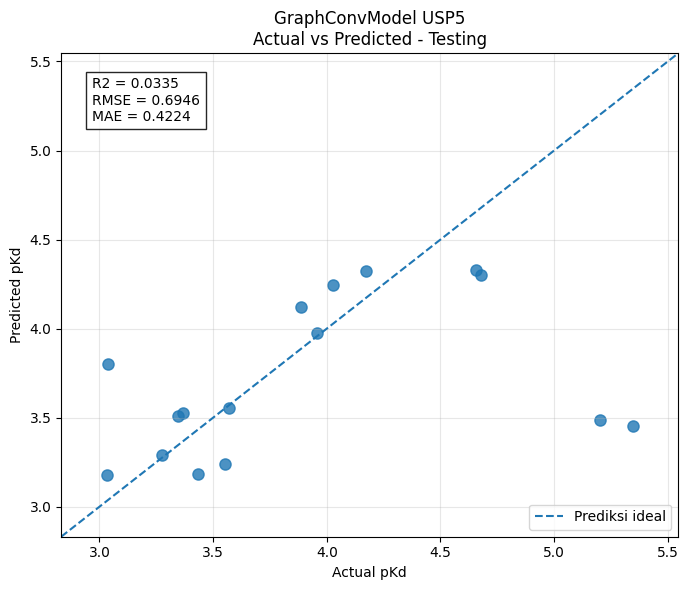

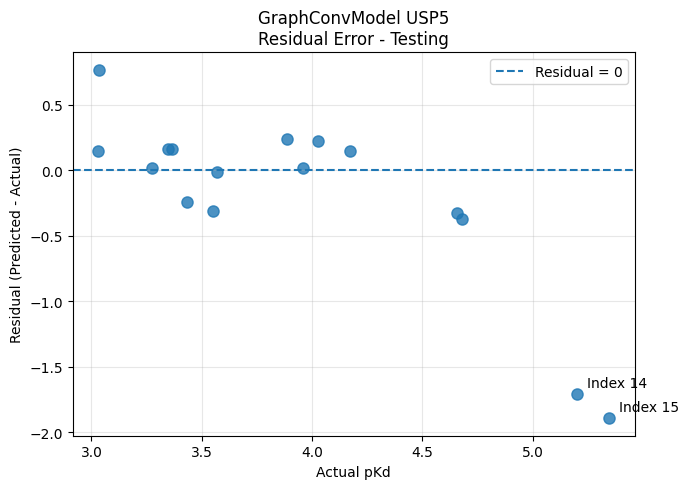


=== RINGKASAN HASIL GNN USP5 ===


,Evaluasi,Jumlah,RMSE,MAE,R2
0,Validation Random Split,20,0.3589,0.2896,0.5476
1,5-Fold Scaffold CV OOF,64,0.4183,0.3333,0.5172
2,Final Testing Repeat,16,0.6946,0.4224,0.0335



=== DUA ERROR TESTING TERBESAR ===


,pKd_Aktual,pKd_Prediksi,Residual,Abs_Error
15,5.3468,3.4519,-1.8949,1.8949
14,5.2007,3.4879,-1.7128,1.7128



=== DOKUMENTASI SELESAI ===
Folder: /data/Aliya/GCN_pKd_Stilben/GraphConv_USP5_80_Final_Repeat/Hasil_Akhir


In [48]:

# ==========================================
# VISUALISASI DAN DOKUMENTASI AKHIR
# GRAPHCONVMODEL USP5 - 80 SENYAWA
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. Ambil hasil final testing yang tersimpan
folder_final = Path(
    "/data/Aliya/GCN_pKd_Stilben/"
    "GraphConv_USP5_80_Final_Repeat"
)

folder_grafik = folder_final / "Hasil_Akhir"
folder_grafik.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    folder_final / "Final_Testing_16.csv"
)

assert len(df) == 16

aktual = df["pKd_Aktual"].to_numpy()
prediksi = df["pKd_Prediksi"].to_numpy()

# Hitung kembali metrik
rmse = np.sqrt(
    mean_squared_error(aktual, prediksi)
)
mae = mean_absolute_error(aktual, prediksi)
r2 = r2_score(aktual, prediksi)

# Residual: prediksi dikurangi aktual
df["Residual"] = prediksi - aktual
df["Abs_Error"] = np.abs(df["Residual"])

print("=== METRIK FINAL TESTING ===")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R2   : {r2:.4f}")

# ==========================================
# 2. ACTUAL VS PREDICTED
# ==========================================

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    aktual,
    prediksi,
    s=65,
    alpha=0.8
)

bawah = min(aktual.min(), prediksi.min()) - 0.2
atas = max(aktual.max(), prediksi.max()) + 0.2

ax.plot(
    [bawah, atas],
    [bawah, atas],
    "--",
    label="Prediksi ideal"
)

ax.set_xlim(bawah, atas)
ax.set_ylim(bawah, atas)

ax.set_xlabel("Actual pKd")
ax.set_ylabel("Predicted pKd")
ax.set_title(
    "GraphConvModel USP5\n"
    "Actual vs Predicted - Testing"
)

ax.text(
    0.05, 0.95,
    f"R2 = {r2:.4f}\n"
    f"RMSE = {rmse:.4f}\n"
    f"MAE = {mae:.4f}",
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict(
        facecolor="white",
        alpha=0.85
    )
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    folder_grafik / "Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==========================================
# 3. RESIDUAL ERROR
# ==========================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    aktual,
    df["Residual"],
    s=65,
    alpha=0.8
)

ax.axhline(
    0,
    linestyle="--",
    label="Residual = 0"
)

# Tandai dua error terbesar
top2 = df.nlargest(2, "Abs_Error")

for idx, baris in top2.iterrows():
    ax.annotate(
        f"Index {idx}",
        (
            baris["pKd_Aktual"],
            baris["Residual"]
        ),
        xytext=(7, 5),
        textcoords="offset points"
    )

ax.set_xlabel("Actual pKd")
ax.set_ylabel("Residual (Predicted - Actual)")
ax.set_title(
    "GraphConvModel USP5\n"
    "Residual Error - Testing"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    folder_grafik / "Residual_Error.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==========================================
# 4. RINGKASAN SELURUH EVALUASI
# ==========================================

ringkasan = pd.DataFrame([
    {
        "Evaluasi": "Validation Random Split",
        "Jumlah": 20,
        "RMSE": 0.3589,
        "MAE": 0.2896,
        "R2": 0.5476
    },
    {
        "Evaluasi": "5-Fold Scaffold CV OOF",
        "Jumlah": 64,
        "RMSE": 0.4183,
        "MAE": 0.3333,
        "R2": 0.5172
    },
    {
        "Evaluasi": "Final Testing Repeat",
        "Jumlah": 16,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }
])

print("\n=== RINGKASAN HASIL GNN USP5 ===")
display(ringkasan.round(4))

print("\n=== DUA ERROR TESTING TERBESAR ===")
display(
    top2[
        ["pKd_Aktual", "pKd_Prediksi",
         "Residual", "Abs_Error"]
    ].round(4)
)

# ==========================================
# 5. SIMPAN SEMUA HASIL
# ==========================================

ringkasan.to_csv(
    folder_grafik / "Ringkasan_Evaluasi.csv",
    index=False
)

df.to_csv(
    folder_grafik / "Prediksi_Testing_Lengkap.csv",
    index=False
)

print("\n=== DOKUMENTASI SELESAI ===")
print("Folder:", folder_grafik)
